In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Find the folder containing the dataset
DATA_DIR = next(
    Path("/kaggle/input").rglob("results.csv")
).parent

# Load all CSV files
tables = {}

for file in DATA_DIR.glob("*.csv"):
    tables[file.stem] = pd.read_csv(
        file,
        na_values=[r"\N"]
    )

# Display table names and dimensions
for name, df in sorted(tables.items()):
    print(f"{name}: {df.shape}")


circuits: (77, 9)
constructor_results: (12625, 5)
constructor_standings: (13391, 7)
constructors: (212, 5)
driver_standings: (34863, 7)
drivers: (861, 9)
lap_times: (589081, 6)
pit_stops: (11371, 7)
qualifying: (10494, 9)
races: (1125, 18)
results: (26759, 18)
seasons: (75, 2)
sprint_results: (360, 16)
status: (139, 2)


In [3]:

# Drivers information
display(tables["drivers"].head())

# Race information
display(tables["races"].head())

# Race results
display(tables["results"].head())

# Qualifying information
display(tables["qualifying"].head())


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [4]:

expected_tables = [
    "circuits",
    "constructors",
    "constructor_results",
    "constructor_standings",
    "drivers",
    "driver_standings",
    "races",
    "results",
    "qualifying",
    "lap_times",
    "pit_stops",
    "sprint_results",
    "seasons",
    "status"
]

missing = set(expected_tables) - set(tables)

print("Number of tables:", len(tables))
print("Missing required tables:", missing)

print(
    "Year range:",
    tables["races"]["year"].min(),
    "-",
    tables["races"]["year"].max()
)


Number of tables: 14
Missing required tables: set()
Year range: 1950 - 2024


# 2. Exploratory Data Analysis (Before Cleaning)

This section explores the raw Formula 1 dataset
to identify missing values, class imbalance,
duplicate records, historical data coverage,
and relationships between starting positions
and podium finishes.

In [5]:

results = tables["results"].copy()

missing = (
    results.isnull().sum()
    .sort_values(ascending=False)
)

missing_percentage = (
    results.isnull().mean() * 100
).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percentage
})

display(missing_summary)


,Missing Count,Missing Percentage
time,19079,71.299376
milliseconds,19079,71.299376
fastestLapSpeed,18507,69.161777
fastestLap,18507,69.161777
fastestLapTime,18507,69.161777
rank,18249,68.197616
position,10953,40.932023
number,6,0.022422
raceId,0,0.000000
resultId,0,0.000000


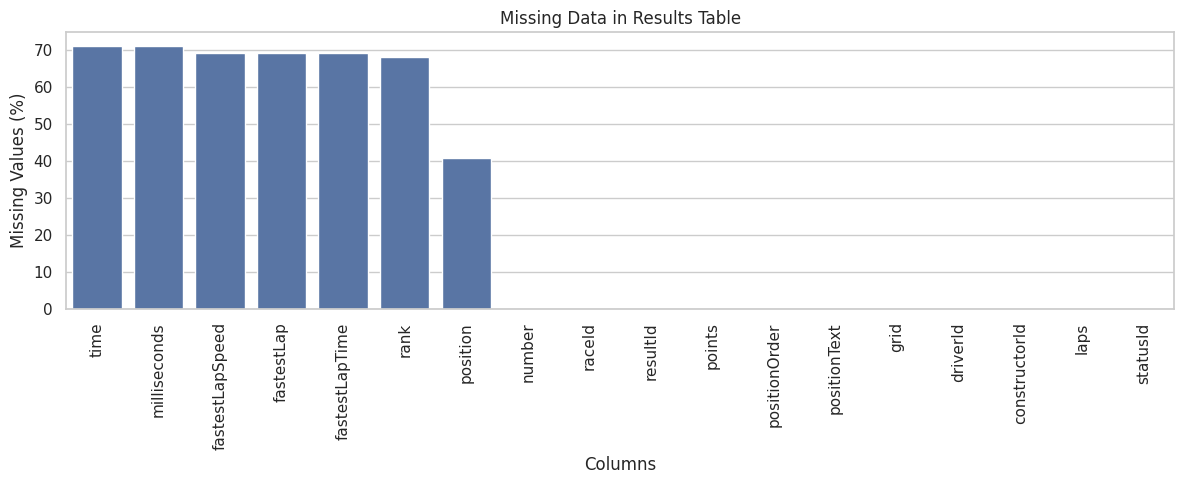

In [6]:

plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing_percentage.index,
    y=missing_percentage.values
)

plt.xticks(rotation=90)
plt.ylabel("Missing Values (%)")
plt.xlabel("Columns")
plt.title("Missing Data in Results Table")
plt.tight_layout()
plt.show()


Class Counts:
podium
0    23362
1     3397
Name: count, dtype: int64

Class Percentages:
podium
0    87.305206
1    12.694794
Name: proportion, dtype: float64


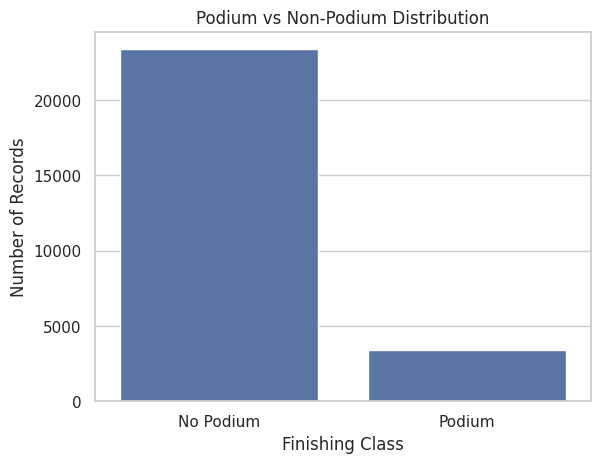

In [7]:

results["podium"] = (
    results["positionOrder"] <= 3
).astype(int)

counts = results["podium"].value_counts()

print("Class Counts:")
print(counts)

print("\nClass Percentages:")
print(
    results["podium"]
    .value_counts(normalize=True) * 100
)

sns.countplot(
    data=results,
    x="podium"
)

plt.xticks([0, 1], ["No Podium", "Podium"])
plt.title("Podium vs Non-Podium Distribution")
plt.xlabel("Finishing Class")
plt.ylabel("Number of Records")
plt.show()


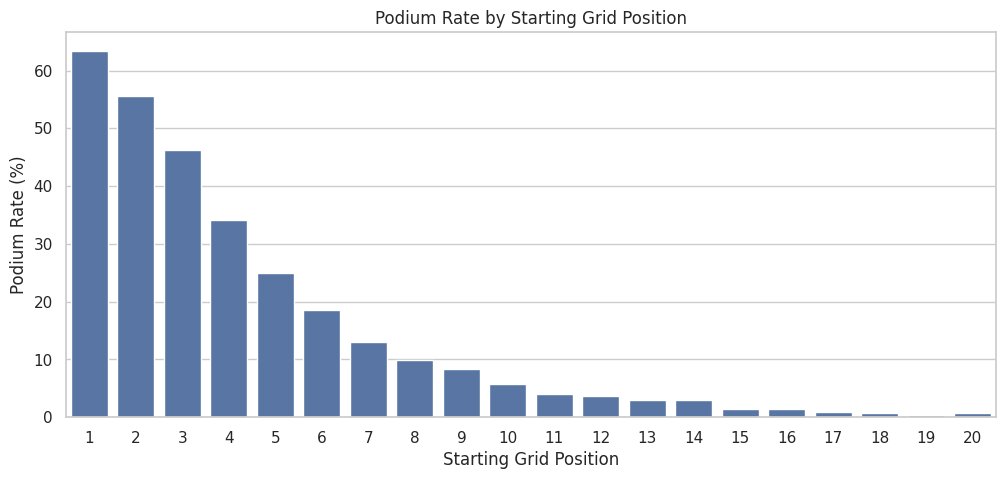

,grid,mean,count,podium_rate
0,1,0.634683,1136,63.468310
1,2,0.556444,1125,55.644444
2,3,0.462832,1130,46.283186
3,4,0.340989,1132,34.098940
4,5,0.250000,1132,25.000000
5,6,0.185778,1125,18.577778
6,7,0.129515,1135,12.951542
7,8,0.099203,1129,9.920283
8,9,0.083039,1132,8.303887
9,10,0.058407,1130,5.840708


In [8]:

# Keep standard starting grid positions 1 to 20
grid_data = results[
    results["grid"].between(1, 20)
].copy()

grid_analysis = (
    grid_data.groupby("grid")["podium"]
    .agg(["mean", "count"])
    .reset_index()
)

grid_analysis["podium_rate"] = (
    grid_analysis["mean"] * 100
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=grid_analysis,
    x="grid",
    y="podium_rate"
)

plt.title("Podium Rate by Starting Grid Position")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.show()

display(grid_analysis)


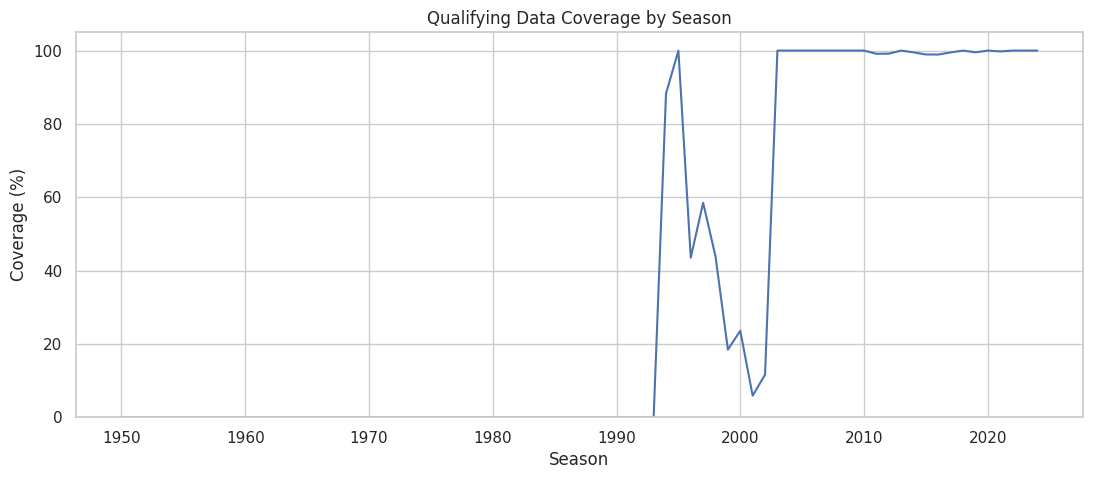

In [9]:

races = tables["races"].copy()
qualifying = tables["qualifying"].copy()

# Unique driver-race entries
entries = results[
    ["raceId", "driverId"]
].drop_duplicates()

entries = entries.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

qualifying_keys = (
    qualifying[["raceId", "driverId"]]
    .drop_duplicates()
    .assign(has_qualifying=1)
)

entries = entries.merge(
    qualifying_keys,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

coverage = (
    entries.groupby("year")["has_qualifying"]
    .apply(lambda x: x.notna().mean() * 100)
)

plt.figure(figsize=(13, 5))
coverage.plot()

plt.title("Qualifying Data Coverage by Season")
plt.xlabel("Season")
plt.ylabel("Coverage (%)")
plt.ylim(0, 105)
plt.grid(True)
plt.show()


In [10]:

duplicates = results[
    results.duplicated(
        ["raceId", "driverId"],
        keep=False
    )
]

print("Number of duplicate rows:", len(duplicates))

print(
    "Number of affected driver-race pairs:",
    duplicates[
        ["raceId", "driverId"]
    ].drop_duplicates().shape[0]
)

display(
    duplicates.sort_values(
        ["raceId", "driverId"]
    ).head(20)
)


Number of duplicate rows: 176
Number of affected driver-race pairs: 85


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,podium
13188,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81,0
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97,0
17362,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60,0
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98,0
17740,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54,0
17743,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54,0
17961,17962,742,475,102,26.0,20,NaN,D,19,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,2,0
17963,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23,0
18062,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6,0
24297,24303,745,418,172,21.0,15,11.0,11,11,0.0,92,NaN,NaN,NaN,NaN,NaN,NaN,18,0


# 3. Data Cleaning and Validation

This section cleans the Formula 1 dataset while preserving
the original raw tables.

We will:
1. Validate primary and foreign keys.
2. Verify missing-value handling.
3. Convert dates and qualifying lap times.
4. Resolve duplicate driver-race records.
5. Compare the data before and after cleaning.

In [11]:

cleaned_tables = {
    name: df.copy()
    for name, df in tables.items()
}

print("Created copies of all tables.")
print("Tables:", len(cleaned_tables))


Created copies of all tables.
Tables: 14


In [12]:

# Primary key checks
primary_keys = {
    "drivers": ["driverId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "constructors": ["constructorId"],
    "circuits": ["circuitId"],
    "status": ["statusId"],
    "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"]
}

for table_name, keys in primary_keys.items():
    df = cleaned_tables[table_name]

    duplicates_count = df.duplicated(keys).sum()
    null_count = df[keys].isna().any(axis=1).sum()

    print(
        f"{table_name}: "
        f"Duplicate PKs = {duplicates_count}, "
        f"Null PKs = {null_count}"
    )


drivers: Duplicate PKs = 0, Null PKs = 0
races: Duplicate PKs = 0, Null PKs = 0
results: Duplicate PKs = 0, Null PKs = 0
qualifying: Duplicate PKs = 0, Null PKs = 0
constructors: Duplicate PKs = 0, Null PKs = 0
circuits: Duplicate PKs = 0, Null PKs = 0
status: Duplicate PKs = 0, Null PKs = 0
driver_standings: Duplicate PKs = 0, Null PKs = 0
constructor_standings: Duplicate PKs = 0, Null PKs = 0


In [13]:

foreign_keys = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("races", "circuitId", "circuits", "circuitId")
]

for child, fk, parent, pk in foreign_keys:
    invalid = (
        ~cleaned_tables[child][fk].isin(
            cleaned_tables[parent][pk]
        )
        & cleaned_tables[child][fk].notna()
    )

    print(
        f"{child}.{fk} -> {parent}.{pk}: "
        f"{invalid.sum()} invalid references"
    )


results.raceId -> races.raceId: 0 invalid references
results.driverId -> drivers.driverId: 0 invalid references
results.constructorId -> constructors.constructorId: 0 invalid references
results.statusId -> status.statusId: 0 invalid references
qualifying.raceId -> races.raceId: 0 invalid references
qualifying.driverId -> drivers.driverId: 0 invalid references
races.circuitId -> circuits.circuitId: 0 invalid references


In [14]:

# Check remaining sentinel strings
for name in ["results", "qualifying", "races"]:
    df = cleaned_tables[name]

    remaining = (
        df.astype("string")
        .eq(r"\N")
        .sum()
        .sum()
    )

    print(name, "remaining sentinels:", remaining)

# Convert dates
cleaned_tables["races"]["date"] = pd.to_datetime(
    cleaned_tables["races"]["date"],
    errors="coerce"
)

cleaned_tables["drivers"]["dob"] = pd.to_datetime(
    cleaned_tables["drivers"]["dob"],
    errors="coerce"
)

# Convert qualifying times to seconds
def lap_to_seconds(value):
    if pd.isna(value):
        return np.nan

    try:
        parts = str(value).split(":")
        seconds = 0.0

        for part in parts:
            seconds = seconds * 60 + float(part)

        return seconds
    except ValueError:
        return np.nan

for col in ["q1", "q2", "q3"]:
    cleaned_tables["qualifying"][
        col + "_seconds"
    ] = cleaned_tables["qualifying"][col].apply(
        lap_to_seconds
    )

display(
    cleaned_tables["qualifying"][
        ["q1", "q1_seconds",
         "q2", "q2_seconds",
         "q3", "q3_seconds"]
    ].head()
)


results remaining sentinels: 0
qualifying remaining sentinels: 0
races remaining sentinels: 0


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


In [15]:

clean_results = cleaned_tables["results"].copy()

original_rows = len(clean_results)

clean_results["grid"] = pd.to_numeric(
    clean_results["grid"],
    errors="coerce"
)

clean_results["positionOrder"] = pd.to_numeric(
    clean_results["positionOrder"],
    errors="coerce"
)

# Prefer records with a recorded positive grid
clean_results["_valid_grid"] = (
    clean_results["grid"] > 0
)

# Sort according to the documented rule
clean_results = clean_results.sort_values(
    [
        "raceId",
        "driverId",
        "_valid_grid",
        "positionOrder",
        "resultId"
    ],
    ascending=[
        True, True, False, True, True
    ]
)

clean_results = clean_results.drop_duplicates(
    subset=["raceId", "driverId"],
    keep="first"
)

clean_results = clean_results.drop(
    columns="_valid_grid"
)

cleaned_tables["results"] = clean_results.copy()

print("Original rows:", original_rows)
print("Cleaned rows:", len(clean_results))
print("Removed rows:", original_rows - len(clean_results))

assert not clean_results.duplicated(
    ["raceId", "driverId"]
).any()

print("Driver-race uniqueness: PASSED")


Original rows: 26759
Cleaned rows: 26668
Removed rows: 91
Driver-race uniqueness: PASSED


In [16]:

before = tables["results"]
after = cleaned_tables["results"]

summary = pd.DataFrame({
    "Before Cleaning": [
        len(before),
        before.duplicated(
            ["raceId", "driverId"]
        ).sum(),
        before["positionOrder"].isna().sum()
    ],
    "After Cleaning": [
        len(after),
        after.duplicated(
            ["raceId", "driverId"]
        ).sum(),
        after["positionOrder"].isna().sum()
    ]
}, index=[
    "Total Rows",
    "Extra Duplicate Rows",
    "Missing Finishing Order"
])

display(summary)


,Before Cleaning,After Cleaning
Total Rows,26759,26668
Extra Duplicate Rows,91,0
Missing Finishing Order,0,0


Cleaning Comparison:


,Stage,Total Records,Extra Duplicate Records,Podium Rate (%)
0,Before Cleaning,26759,91,12.695
1,After Cleaning,26668,0,12.731


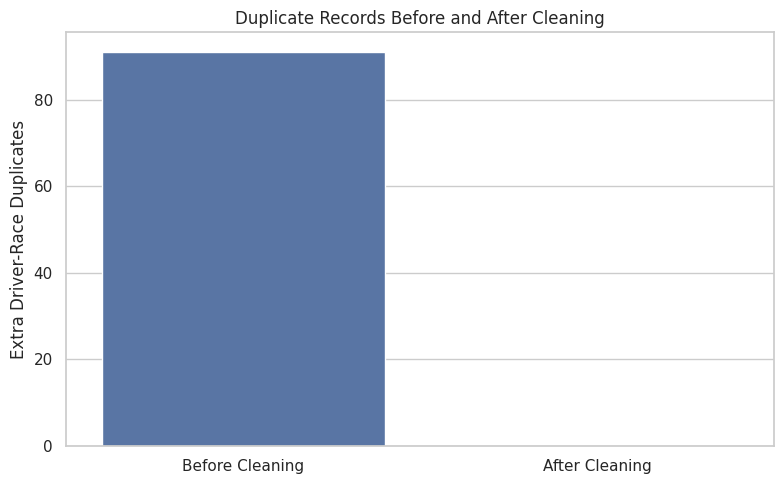

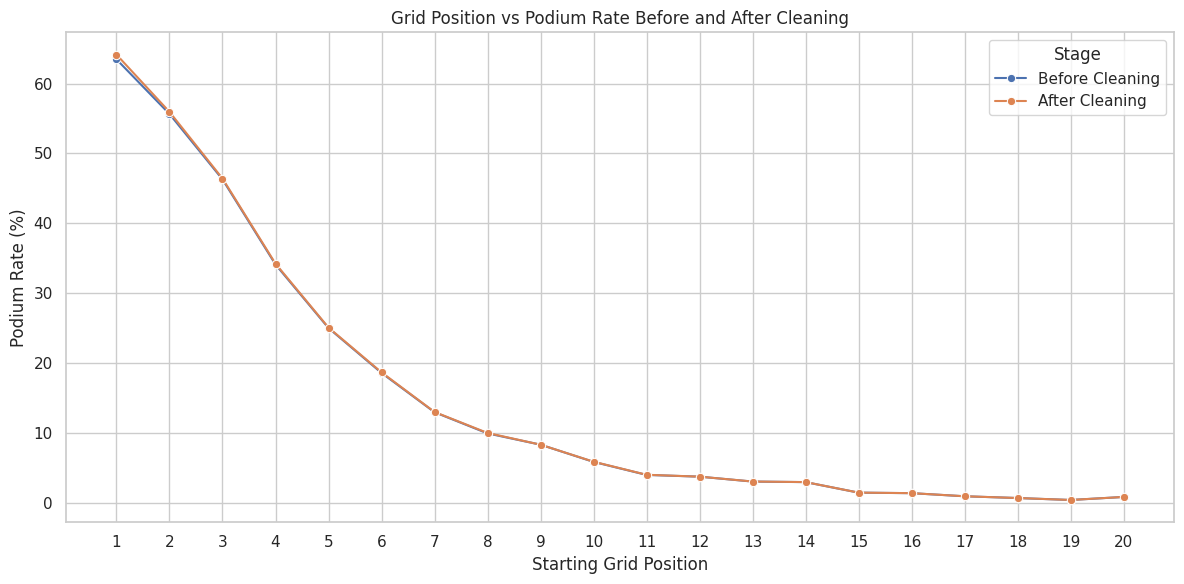

Before-and-after EDA completed successfully.


In [17]:

# Before-and-after cleaning EDA

raw_results = tables["results"].copy()
clean_results_eda = cleaned_tables["results"].copy()

eda_summary = []
grid_comparison = []

for stage, df in [
    ("Before Cleaning", raw_results),
    ("After Cleaning", clean_results_eda)
]:

    temp = df.copy()

    temp["grid_numeric"] = pd.to_numeric(
        temp["grid"],
        errors="coerce"
    )

    temp["podium"] = (
        pd.to_numeric(
            temp["positionOrder"],
            errors="coerce"
        ).isin([1, 2, 3])
    ).astype(int)

    eda_summary.append({
        "Stage": stage,
        "Total Records": len(temp),
        "Extra Duplicate Records": temp.duplicated(
            ["raceId", "driverId"]
        ).sum(),
        "Podium Rate (%)": temp["podium"].mean() * 100
    })

    # Keep standard grid positions for comparison
    grid_temp = temp[
        temp["grid_numeric"].between(1, 20)
    ]

    rates = (
        grid_temp.groupby("grid_numeric")["podium"]
        .mean()
        .mul(100)
        .reset_index(name="Podium Rate (%)")
    )

    rates["Stage"] = stage
    grid_comparison.append(rates)


cleaning_eda = pd.DataFrame(eda_summary)
grid_comparison = pd.concat(
    grid_comparison,
    ignore_index=True
)

print("Cleaning Comparison:")
display(cleaning_eda.round(3))


# Plot 1: Duplicate records

plt.figure(figsize=(8, 5))

sns.barplot(
    data=cleaning_eda,
    x="Stage",
    y="Extra Duplicate Records"
)

plt.title("Duplicate Records Before and After Cleaning")
plt.xlabel("")
plt.ylabel("Extra Driver-Race Duplicates")
plt.tight_layout()
plt.show()


# Plot 2: Podium rate by grid position

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=grid_comparison,
    x="grid_numeric",
    y="Podium Rate (%)",
    hue="Stage",
    marker="o"
)

plt.title(
    "Grid Position vs Podium Rate Before and After Cleaning"
)

plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.xticks(range(1, 21))
plt.tight_layout()
plt.show()

print("Before-and-after EDA completed successfully.")


### Before-and-After Cleaning — EDA Findings

The data-cleaning process reduced the number of result records from 26,759 to 26,668 by removing 91 extra duplicate driver-race records. After cleaning, no duplicate combinations of `raceId` and `driverId` remained.

The overall podium rate increased slightly from 12.695% before cleaning to 12.731% afterward, a difference of approximately 0.036 percentage points.

The duplicate-count visualization confirms that deduplication successfully removed the identified duplicate records. The comparison of starting-grid position against podium conversion rate shows that the overall relationship remained similar before and after cleaning.

These findings suggest that cleaning had a limited impact on the main exploratory patterns. However, removing duplicates was essential for maintaining a consistent analytical unit: one observation per driver per race. Without this correction, some observations would receive excessive weight in subsequent analyses and model training.

The comparison also demonstrates that cleaning quality should be assessed through both structural validation and changes in the data distribution.

# 4. Data Integration and Table Joins

This section joins the cleaned Formula 1 tables
using primary and foreign keys.

The objective is to construct one analytical
table containing race, driver, constructor,
circuit, qualifying, and result information.

All joins preserve one row per driver-race.

In [18]:

# Start from cleaned results
analysis_df = cleaned_tables["results"].copy()

# Prepare race details
race_info = cleaned_tables["races"][
    ["raceId", "year", "round", "date",
     "name", "circuitId"]
].rename(columns={
    "name": "race_name"
})

# Join race details
analysis_df = analysis_df.merge(
    race_info,
    on="raceId",
    how="left",
    validate="many_to_one"
)

display(analysis_df.head())


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,round,date,race_name,circuitId
0,7573,1,1,1,1.0,18,NaN,D,20,0.0,...,39.0,13.0,1:29.020,214.455,2,2009,1,2009-03-29,Australian Grand Prix,1
1,7563,1,2,2,6.0,9,10.0,10,10,0.0,...,48.0,5.0,1:28.283,216.245,1,2009,1,2009-03-29,Australian Grand Prix,1
2,7559,1,3,3,16.0,5,6.0,6,6,3.0,...,48.0,1.0,1:27.706,217.668,1,2009,1,2009-03-29,Australian Grand Prix,1
3,7558,1,4,4,7.0,10,5.0,5,5,4.0,...,53.0,9.0,1:28.712,215.199,1,2009,1,2009-03-29,Australian Grand Prix,1
4,7572,1,5,1,2.0,12,NaN,R,19,0.0,...,NaN,NaN,NaN,NaN,4,2009,1,2009-03-29,Australian Grand Prix,1


In [19]:

# Prepare circuits table
circuit_info = cleaned_tables["circuits"][
    ["circuitId", "name", "country"]
].rename(columns={
    "name": "circuit_name",
    "country": "circuit_country"
})

analysis_df = analysis_df.merge(
    circuit_info,
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# Prepare drivers table
driver_info = cleaned_tables["drivers"][
    ["driverId", "forename",
     "surname", "nationality"]
]

analysis_df = analysis_df.merge(
    driver_info,
    on="driverId",
    how="left",
    validate="many_to_one"
)

print("Circuit and driver information joined.")
display(analysis_df.head())


Circuit and driver information joined.


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,year,round,date,race_name,circuitId,circuit_name,circuit_country,forename,surname,nationality
0,7573,1,1,1,1.0,18,NaN,D,20,0.0,...,2009,1,2009-03-29,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Lewis,Hamilton,British
1,7563,1,2,2,6.0,9,10.0,10,10,0.0,...,2009,1,2009-03-29,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Nick,Heidfeld,German
2,7559,1,3,3,16.0,5,6.0,6,6,3.0,...,2009,1,2009-03-29,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Nico,Rosberg,German
3,7558,1,4,4,7.0,10,5.0,5,5,4.0,...,2009,1,2009-03-29,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Fernando,Alonso,Spanish
4,7572,1,5,1,2.0,12,NaN,R,19,0.0,...,2009,1,2009-03-29,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Heikki,Kovalainen,Finnish


In [20]:

constructor_info = cleaned_tables["constructors"][
    ["constructorId", "name"]
].rename(columns={
    "name": "constructor_name"
})

analysis_df = analysis_df.merge(
    constructor_info,
    on="constructorId",
    how="left",
    validate="many_to_one"
)

print("Constructor information joined.")


Constructor information joined.


In [21]:

qualifying_info = cleaned_tables["qualifying"][
    [
        "raceId", "driverId", "position",
        "q1_seconds", "q2_seconds", "q3_seconds"
    ]
].rename(columns={
    "position": "qualifying_position"
})

# Check uniqueness before merging
assert not qualifying_info.duplicated(
    ["raceId", "driverId"]
).any(), "Duplicate qualifying entries detected"

analysis_df = analysis_df.merge(
    qualifying_info,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

print("Qualifying information joined.")


Qualifying information joined.


In [22]:

status_info = cleaned_tables["status"].rename(
    columns={"status": "status_description"}
)

analysis_df = analysis_df.merge(
    status_info,
    on="statusId",
    how="left",
    validate="many_to_one"
)

print("Status information joined.")


Status information joined.


In [23]:

# Create binary target
analysis_df["podium"] = (
    analysis_df["positionOrder"] <= 3
).astype(int)

# Limit to required historical period
analysis_df = analysis_df[
    analysis_df["year"].between(1950, 2024)
].copy()

# Verify unique driver-race records
assert not analysis_df.duplicated(
    ["raceId", "driverId"]
).any()

# Verify joins did not unexpectedly lose rows
assert len(analysis_df) == len(
    cleaned_tables["results"]
)

# Check essential joins
for col in [
    "race_name",
    "circuit_name",
    "forename",
    "constructor_name",
    "status_description"
]:
    print(
        col,
        "missing values:",
        analysis_df[col].isna().sum()
    )

print("\nAnalytical dataset shape:")
print(analysis_df.shape)

display(
    analysis_df[
        [
            "year", "race_name",
            "forename", "surname",
            "constructor_name",
            "circuit_name",
            "grid", "qualifying_position",
            "positionOrder", "podium"
        ]
    ].head(10)
)


race_name missing values: 0
circuit_name missing values: 0
forename missing values: 0
constructor_name missing values: 0
status_description missing values: 0

Analytical dataset shape:
(26668, 35)


,year,race_name,forename,surname,constructor_name,circuit_name,grid,qualifying_position,positionOrder,podium
0,2009,Australian Grand Prix,Lewis,Hamilton,McLaren,Albert Park Grand Prix Circuit,18,15.0,20,0
1,2009,Australian Grand Prix,Nick,Heidfeld,BMW Sauber,Albert Park Grand Prix Circuit,9,11.0,10,0
2,2009,Australian Grand Prix,Nico,Rosberg,Williams,Albert Park Grand Prix Circuit,5,5.0,6,0
3,2009,Australian Grand Prix,Fernando,Alonso,Renault,Albert Park Grand Prix Circuit,10,12.0,5,0
4,2009,Australian Grand Prix,Heikki,Kovalainen,McLaren,Albert Park Grand Prix Circuit,12,14.0,19,0
5,2009,Australian Grand Prix,Kazuki,Nakajima,Williams,Albert Park Grand Prix Circuit,11,13.0,18,0
6,2009,Australian Grand Prix,Sébastien,Bourdais,Toro Rosso,Albert Park Grand Prix Circuit,17,20.0,8,0
7,2009,Australian Grand Prix,Kimi,Räikkönen,Ferrari,Albert Park Grand Prix Circuit,7,9.0,15,0
8,2009,Australian Grand Prix,Robert,Kubica,BMW Sauber,Albert Park Grand Prix Circuit,4,4.0,14,0
9,2009,Australian Grand Prix,Timo,Glock,Toyota,Albert Park Grand Prix Circuit,19,6.0,4,0


# 5. Data Engineering Questions

## Question 1: Front-Row Podium Conversion by Circuit

This analysis measures how frequently drivers starting
from grid positions 1 and 2 finish on the podium.

We compare races before 2014 with races from
2014 onwards and distinguish actual starting
grid position from qualifying position.

In [24]:

# Exclude identifiable non-starters from Q1

status_q1 = (
    analysis_df["status_description"]
    .fillna("")
    .str.strip()
    .str.lower()
)

non_start_statuses_q1 = {
    "did not start",
    "did not qualify",
    "did not prequalify",
    "did not pre-qualify",
    "withdrawn",
    "107% rule"
}

no_start = (
    status_q1.isin(non_start_statuses_q1)
    | (
        status_q1.eq("withdrew")
        & analysis_df["laps"].eq(0)
    )
)

q1_clean = analysis_df.loc[
    ~no_start
].copy()

print("Excluded non-starter records:", no_start.sum())

print(
    "Remaining analytical records:",
    len(q1_clean)
)


Excluded non-starter records: 1587
Remaining analytical records: 25081


In [25]:

# Select drivers who actually started from the front row
front_row = q1_clean[
    q1_clean["grid"].isin([1, 2])
].copy()

# Divide races into two periods
front_row["era"] = np.where(
    front_row["year"] < 2014,
    "Before 2014",
    "2014 onwards"
)

print("Front-row records:", len(front_row))
display(front_row.head())


Front-row records: 2240


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,surname,nationality,constructor_name,qualifying_position,q1_seconds,q2_seconds,q3_seconds,status_description,podium,era
15,7554,1,18,23,22.0,1,1.0,1,1,10.0,...,Button,British,Brawn,1.0,85.211,84.855,86.202,Finished,1,Before 2014
18,7555,1,22,23,23.0,2,2.0,2,2,8.0,...,Barrichello,Brazilian,Brawn,2.0,85.006,84.783,86.505,Finished,1,Before 2014
32,7577,2,15,7,9.0,2,4.0,4,4,2.5,...,Trulli,Italian,Toyota,2.0,94.745,93.990,95.273,Finished,0,Before 2014
35,7574,2,18,23,22.0,1,1.0,1,1,5.0,...,Button,British,Brawn,1.0,95.058,93.784,95.181,Finished,1,Before 2014
43,7602,3,4,4,7.0,2,9.0,9,9,0.0,...,Alonso,Spanish,Renault,2.0,96.443,95.803,96.381,Finished,0,Before 2014


In [26]:

circuit_rates = (
    front_row.groupby(
        ["era", "circuit_name"]
    )
    .agg(
        front_row_starts=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

circuit_rates["podium_rate"] = (
    circuit_rates["podium_finishes"]
    / circuit_rates["front_row_starts"]
    * 100
)

# Require at least 10 observations
# to reduce misleading small-sample rankings
ranked_circuits = circuit_rates[
    circuit_rates["front_row_starts"] >= 10
].copy()

display(
    ranked_circuits.sort_values(
        ["era", "podium_rate"],
        ascending=[True, False]
    )
)


,era,circuit_name,front_row_starts,podium_finishes,podium_rate
30,2014 onwards,Suzuka Circuit,18,16,88.888889
31,2014 onwards,Yas Marina Circuit,22,19,86.363636
13,2014 onwards,Circuit de Monaco,20,17,85.000000
12,2014 onwards,Circuit de Barcelona-Catalunya,22,18,81.818182
14,2014 onwards,Circuit de Spa-Francorchamps,22,18,81.818182
...,...,...,...,...,...
72,Before 2014,Kyalami,40,17,42.500000
90,Before 2014,Scandinavian Raceway,12,5,41.666667
45,Before 2014,Brands Hatch,28,11,39.285714
40,Before 2014,Autódromo Internacional Nelson Piquet,20,7,35.000000


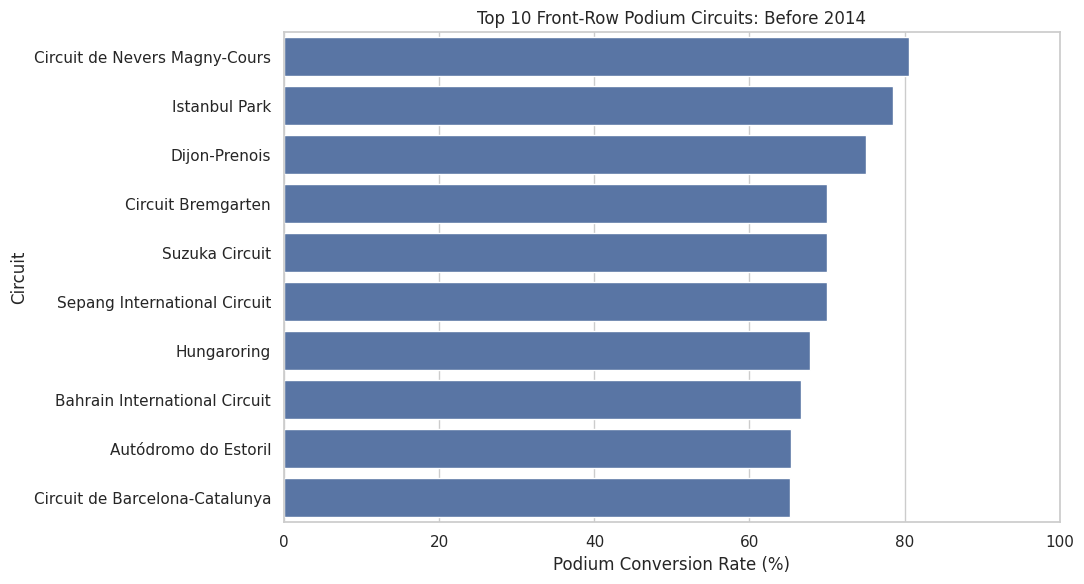

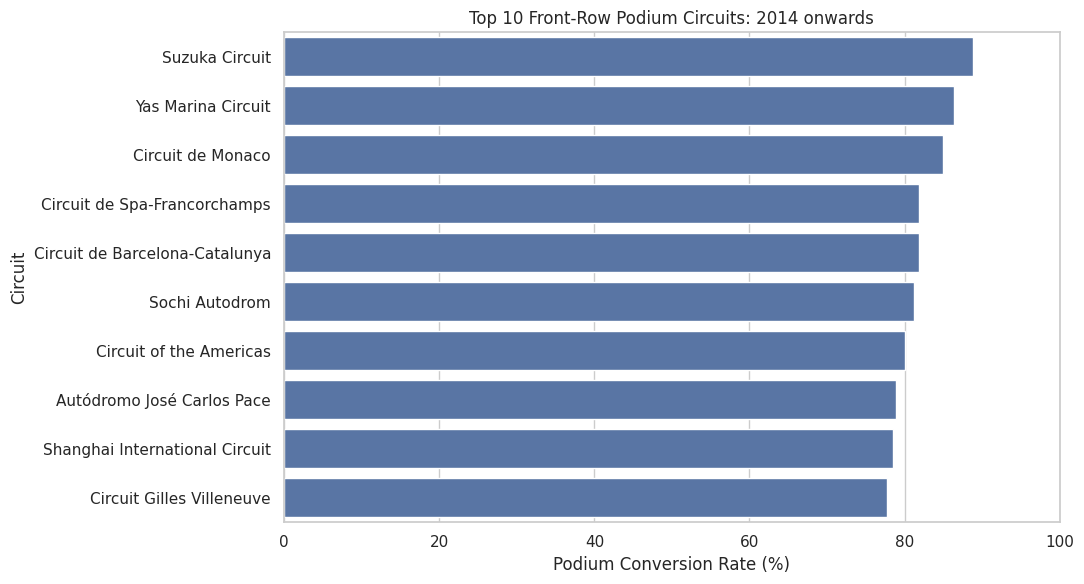

In [27]:

for era in ["Before 2014", "2014 onwards"]:

    top_circuits = (
        ranked_circuits[
            ranked_circuits["era"] == era
        ]
        .sort_values(
            "podium_rate", ascending=False
        )
        .head(10)
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=top_circuits,
        x="podium_rate",
        y="circuit_name"
    )

    plt.title(
        f"Top 10 Front-Row Podium Circuits: {era}"
    )
    plt.xlabel("Podium Conversion Rate (%)")
    plt.ylabel("Circuit")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()


In [28]:

comparison = ranked_circuits.pivot(
    index="circuit_name",
    columns="era",
    values="podium_rate"
).dropna()

comparison["Rank Before 2014"] = (
    comparison["Before 2014"]
    .rank(ascending=False, method="min")
)

comparison["Rank 2014 onwards"] = (
    comparison["2014 onwards"]
    .rank(ascending=False, method="min")
)

comparison["Rank Change"] = (
    comparison["Rank Before 2014"]
    - comparison["Rank 2014 onwards"]
)

display(
    comparison.sort_values(
        "Rank 2014 onwards"
    )
)


era,2014 onwards,Before 2014,Rank Before 2014,Rank 2014 onwards,Rank Change
circuit_name,,,,,
Suzuka Circuit,88.888889,70.000000,1.0,1.0,0.0
Yas Marina Circuit,86.363636,60.000000,6.0,2.0,4.0
Circuit de Monaco,85.000000,49.166667,15.0,3.0,12.0
Circuit de Barcelona-Catalunya,81.818182,65.217391,4.0,4.0,0.0
Circuit de Spa-Francorchamps,81.818182,55.056180,12.0,4.0,8.0
Autódromo José Carlos Pace,78.947368,59.677419,8.0,6.0,2.0
Shanghai International Circuit,78.571429,65.000000,5.0,7.0,-2.0
Circuit Gilles Villeneuve,77.777778,52.941176,13.0,8.0,5.0
Silverstone Circuit,75.000000,56.382979,10.0,9.0,1.0


In [29]:

# Compare only rows with qualifying information
# Exclude identifiable non-starters using q1_clean

qual_comparison = q1_clean[
    q1_clean["qualifying_position"].notna()
].copy()

qual_comparison["qualified_front_row"] = (
    qual_comparison["qualifying_position"]
    .isin([1, 2])
)

qual_comparison["started_front_row"] = (
    qual_comparison["grid"].isin([1, 2])
)

# Identify differences between qualifying
# front row and actual front row
differences = qual_comparison[
    qual_comparison["qualified_front_row"]
    != qual_comparison["started_front_row"]
]

print(
    "Rows where front-row status differs:",
    len(differences)
)

display(
    differences[
        [
            "year",
            "race_name",
            "forename",
            "surname",
            "qualifying_position",
            "grid"
        ]
    ].head(15)
)

# Compare podium conversion rates
grid_rate = qual_comparison.loc[
    qual_comparison["started_front_row"],
    "podium"
].mean() * 100

qual_rate = qual_comparison.loc[
    qual_comparison["qualified_front_row"],
    "podium"
].mean() * 100

print(f"Actual front-row rate: {grid_rate:.2f}%")
print(f"Qualifying front-row rate: {qual_rate:.2f}%")


Rows where front-row status differs: 74


,year,race_name,forename,surname,qualifying_position,grid
929,2007,Hungarian Grand Prix,Nick,Heidfeld,3.0,2
931,2007,Hungarian Grand Prix,Fernando,Alonso,1.0,6
1676,2005,British Grand Prix,Kimi,Räikkönen,2.0,12
1682,2005,British Grand Prix,Jenson,Button,3.0,2
1754,2005,Italian Grand Prix,Fernando,Alonso,3.0,2
1755,2005,Italian Grand Prix,Kimi,Räikkönen,1.0,11
1962,2004,Monaco Grand Prix,Jenson,Button,3.0,2
1965,2004,Monaco Grand Prix,Ralf,Schumacher,2.0,12
8070,2010,Canadian Grand Prix,Mark,Webber,2.0,7
8072,2010,Canadian Grand Prix,Sebastian,Vettel,3.0,2


Actual front-row rate: 70.33%
Qualifying front-row rate: 68.97%


Method                                       Qualifying  Starting Grid  \
era          circuit_name                                                
2014 onwards Autódromo José Carlos Pace       65.000000      78.947368   
Before 2014  Circuit de Monaco                64.285714      71.428571   
2014 onwards Circuit Gilles Villeneuve        72.222222      77.777778   
             Autódromo Hermanos Rodríguez     55.555556      61.111111   
             Circuit of the Americas          75.000000      80.000000   
             Yas Marina Circuit               81.818182      86.363636   
Before 2014  Autodromo Nazionale di Monza     65.384615      69.230769   
2014 onwards Red Bull Ring                    69.230769      73.076923   
Before 2014  Hungaroring                      65.384615      69.230769   
             Circuit de Barcelona-Catalunya   63.333333      66.666667   
2014 onwards Circuit de Monaco                85.000000      85.000000   
Before 2014  Circuit Gilles Villeneuve        57.692308      57.692308   
2014 onwards Bahrain International Circuit    66.666667      66.666667   
             Autodromo Nazionale di Monza     72.727273      72.727273   
             Albert Park Grand Prix Circuit   72.222222      72.222222   
             Circuit de Barcelona-Catalunya   81.818182      81.818182   
             Marina Bay Street Circuit        72.222222      72.222222   
             Sochi Autodrom                   81.250000      81.250000   
             Silverstone Circuit              75.000000      75.000000   
Before 2014  Albert Park Grand Prix Circuit   53.125000      53.125000   
2014 onwards Suzuka Circuit                   88.888889      88.888889   
Before 2014  Autodromo Enzo e Dino Ferrari    65.000000      65.000000   
2014 onwards Shanghai International Circuit   78.571429      78.571429   
             Hungaroring                      59.090909      59.090909   
             Circuit de Spa-Francorchamps     81.818182      81.818182   
Before 2014  Marina Bay Street Circuit        58.333333      58.333333   
             Bahrain International Circuit    66.666667      66.666667   
             Autódromo José Carlos Pace       58.823529      58.823529   
             Circuit de Nevers Magny-Cours    88.888889      88.888889   
             Circuit de Spa-Francorchamps     54.166667      54.166667   
             Hockenheimring                   68.181818      68.181818   
             Indianapolis Motor Speedway      80.000000      80.000000   
             Istanbul Park                    78.571429      78.571429   
             Yas Marina Circuit               60.000000      60.000000   
             Nürburgring                      55.000000      55.000000   
             Sepang International Circuit     66.666667      66.666667   
             Suzuka Circuit                   76.923077      76.923077   
             Valencia Street Circuit          60.000000      60.000000   
             Silverstone Circuit              65.625000      62.500000   
             Shanghai International Circuit   70.000000      65.000000   
2014 onwards Baku City Circuit                68.750000      62.500000   

Method                                       Difference (pp)  
era          circuit_name                                     
2014 onwards Autódromo José Carlos Pace            13.947368  
Before 2014  Circuit de Monaco                      7.142857  
2014 onwards Circuit Gilles Villeneuve              5.555556  
             Autódromo Hermanos Rodríguez           5.555556  
             Circuit of the Americas                5.000000  
             Yas Marina Circuit                     4.545455  
Before 2014  Autodromo Nazionale di Monza           3.846154  
2014 onwards Red Bull Ring                          3.846154  
Before 2014  Hungaroring                            3.846154  
             Circuit de Barcelona-Catalunya         3.333333  
2014 onwards Circuit de Monaco                      0.000000 

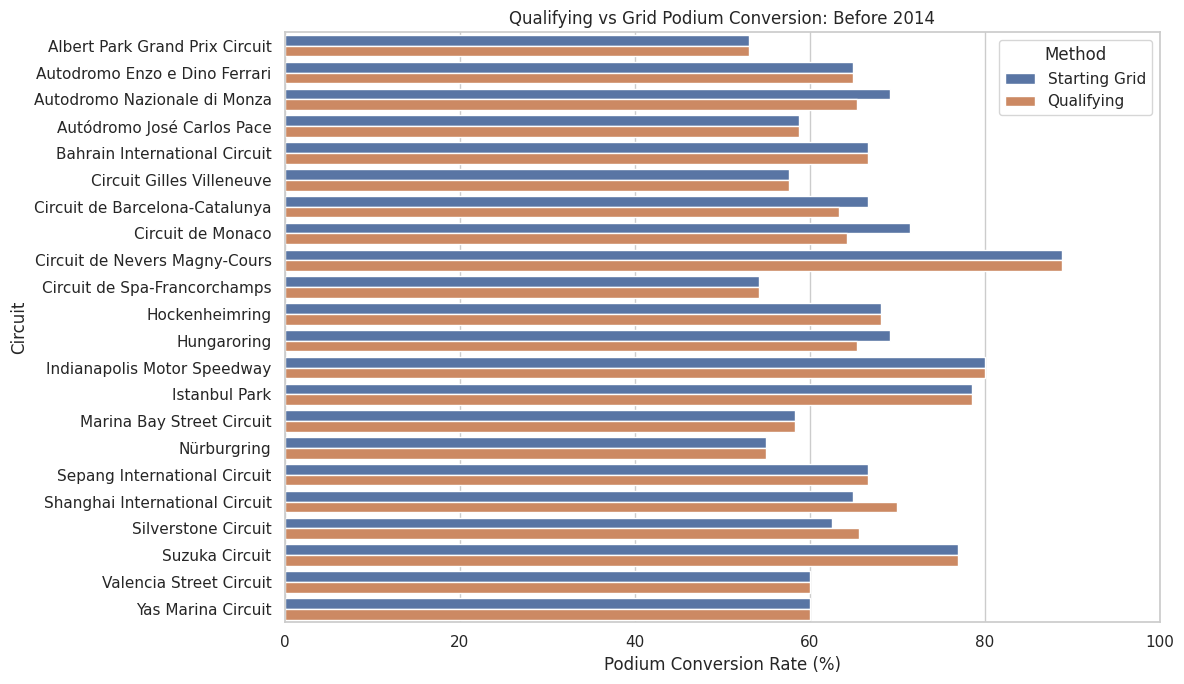

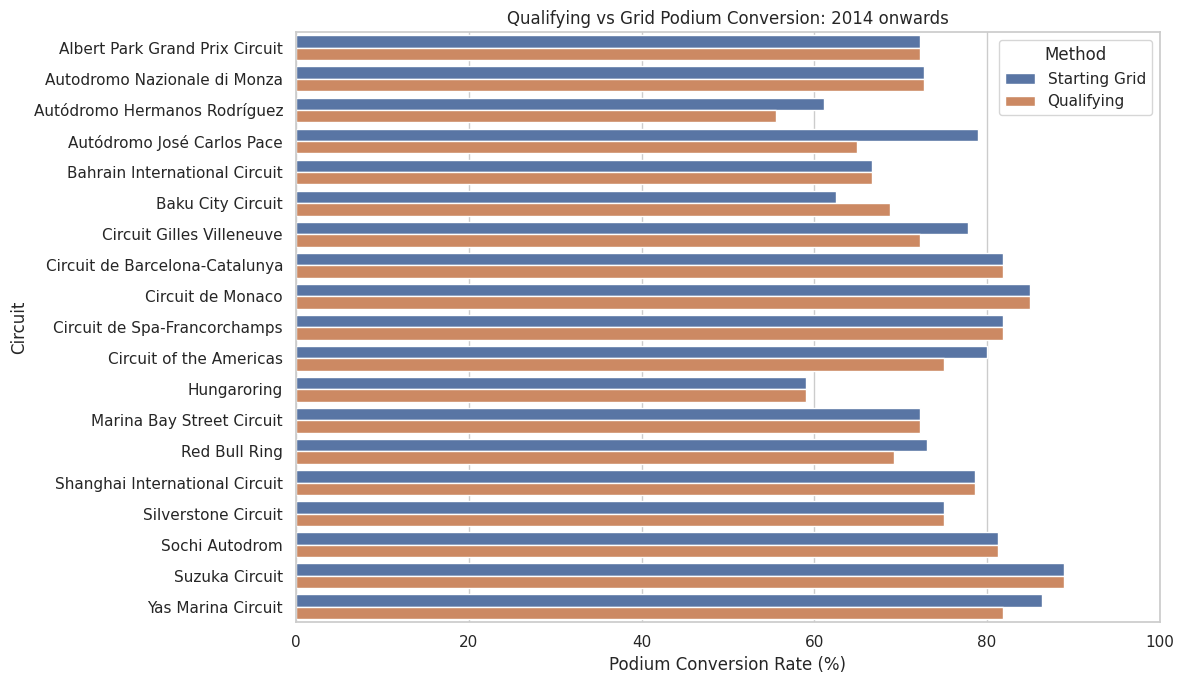

In [30]:

# Question 1: Qualifying vs Grid by Circuit and Era
# Exclude identifiable non-starters

q1_data = q1_clean[
    q1_clean["qualifying_position"].notna()
].copy()

q1_data["era"] = np.where(
    q1_data["year"] < 2014,
    "Before 2014",
    "2014 onwards"
)

comparisons = []

for label, column in [
    ("Starting Grid", "grid"),
    ("Qualifying", "qualifying_position")
]:
    subset = q1_data[
        q1_data[column].isin([1, 2])
    ]

    rates = (
        subset.groupby(["era", "circuit_name"])
        .agg(
            starts=("podium", "size"),
            podiums=("podium", "sum")
        )
        .reset_index()
    )

    rates["podium_rate"] = (
        rates["podiums"] / rates["starts"] * 100
    )

    rates["Method"] = label
    comparisons.append(rates)

q1_comparison = pd.concat(
    comparisons,
    ignore_index=True
)

# Filter out circuits with small samples
q1_comparison = q1_comparison[
    q1_comparison["starts"] >= 10
]

# Compare qualifying and actual grid rates
q1_pivot = q1_comparison.pivot(
    index=["era", "circuit_name"],
    columns="Method",
    values="podium_rate"
).dropna()

q1_pivot["Difference (pp)"] = (
    q1_pivot["Starting Grid"]
    - q1_pivot["Qualifying"]
)

display(
    q1_pivot.sort_values(
        "Difference (pp)",
        ascending=False
    )
)

# Plot the comparison for each era
for era in ["Before 2014", "2014 onwards"]:

    era_data = q1_comparison[
        q1_comparison["era"] == era
    ]

    valid_circuits = q1_pivot.loc[era].index

    era_data = era_data[
        era_data["circuit_name"].isin(
            valid_circuits
        )
    ]

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=era_data,
        x="podium_rate",
        y="circuit_name",
        hue="Method"
    )

    plt.title(
        f"Qualifying vs Grid Podium Conversion: {era}"
    )

    plt.xlabel("Podium Conversion Rate (%)")
    plt.ylabel("Circuit")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()


In [31]:

# Audit potential non-starters in front-row analysis

status = (
    analysis_df["status_description"]
    .fillna("")
    .str.strip()
    .str.lower()
)

non_start_statuses = {
    "did not start",
    "did not qualify",
    "did not prequalify",
    "did not pre-qualify",
    "withdrawn",
    "107% rule"
}

possible_non_starter = (
    status.isin(non_start_statuses)
    | (
        status.eq("withdrew")
        & analysis_df["laps"].eq(0)
    )
)

front_row_candidates = (
    analysis_df["grid"].isin([1, 2])
    | analysis_df["qualifying_position"].isin([1, 2])
)

suspect_rows = analysis_df[
    front_row_candidates & possible_non_starter
]

print(
    "Potential front-row non-starters:",
    len(suspect_rows)
)

display(
    suspect_rows[
        [
            "year", "race_name",
            "surname", "grid",
            "qualifying_position",
            "laps", "status_description"
        ]
    ]
)


Potential front-row non-starters: 3


,year,race_name,surname,grid,qualifying_position,laps,status_description
1636,2005,United States Grand Prix,Räikkönen,2,2.0,0,Withdrew
1640,2005,United States Grand Prix,Trulli,1,1.0,0,Withdrew
8946,1989,Australian Grand Prix,Prost,2,NaN,0,Withdrew


### Question 1 — Findings and Interpretation

This analysis investigated which Formula 1 circuits have the highest podium conversion rates for drivers starting in grid positions 1 and 2, and whether circuit rankings changed from the pre-2014 period to 2014–2024.

**Circuit rankings:** Before 2014, Circuit de Nevers Magny-Cours achieved one of the highest front-row podium conversion rates, at 88.89%. During 2014–2024, Suzuka Circuit ranked highest at 88.89%, with 16 podium finishes from 18 front-row starts.

Among the 16 circuits with sufficient observations in both periods, rankings changed considerably. Circuit de Monaco improved from 15th to 3rd, whereas Hungaroring fell from 2nd to 16th.

**Qualifying versus starting grid:** The analysis also compared drivers who qualified in positions 1 and 2 with those who actually started from these positions. The results showed differences at several circuits. For example, during 2014–2024, Autódromo José Carlos Pace recorded a qualifying front-row conversion rate of 65.00%, compared with 78.95% for the actual starting grid. At Suzuka, both rates were 88.89%.

These differences demonstrate the importance of distinguishing qualifying positions from starting-grid positions, since penalties and grid adjustments may change the starting order.

**Limitations:** Historical qualifying data is incomplete, particularly for earlier seasons. Therefore, qualifying-versus-grid comparisons were restricted to records with available qualifying information. Circuit rankings also depend on sample size, historical regulations, constructor performance, and driver ability. The results represent observed associations, not causal effects.

## Question 2: Home-Race Advantage

We investigate whether drivers achieve higher podium
rates when racing in their home countries.

Driver nationalities are standardized to countries,
then home and away podium rates are compared within
similar starting-grid groups.

In [32]:

print("Driver nationalities:")
print(sorted(
    analysis_df["nationality"].dropna().unique()
))

print("\nCircuit countries:")
print(sorted(
    analysis_df["circuit_country"].dropna().unique()
))


Driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

Circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


In [33]:

nationality_to_country = {
    "American": "USA",
    "Argentine": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Brazilian": "Brazil",
    "British": "UK",
    "Canadian": "Canada",
    "Chilean": "Chile",
    "Chinese": "China",
    "Colombian": "Colombia",
    "Czech": "Czech Republic",
    "Danish": "Denmark",
    "Dutch": "Netherlands",
    "East German": "Germany",
    "Finnish": "Finland",
    "French": "France",
    "German": "Germany",
    "Hungarian": "Hungary",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Italian": "Italy",
    "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "New Zealander": "New Zealand",
    "Polish": "Poland",
    "Portuguese": "Portugal",
    "Russian": "Russia",
    "South African": "South Africa",
    "Spanish": "Spain",
    "Swedish": "Sweden",
    "Swiss": "Switzerland",
    "Thai": "Thailand",
    "Uruguayan": "Uruguay",
    "Venezuelan": "Venezuela"
}

home_df = analysis_df.copy()

home_df["driver_country"] = (
    home_df["nationality"].map(
        nationality_to_country
    )
)

home_df["home_race"] = (
    home_df["driver_country"]
    == home_df["circuit_country"]
).astype("boolean")

# Unknown nationalities are not automatically away
home_df.loc[
    home_df["driver_country"].isna(),
    "home_race"
] = pd.NA

print("Unmapped nationalities:")
print(
    home_df.loc[
        home_df["driver_country"].isna(),
        "nationality"
    ].value_counts()
)

display(
    home_df[
        ["forename", "surname", "nationality",
         "driver_country", "circuit_country",
         "home_race"]
    ].head(10)
)


Unmapped nationalities:
nationality
Rhodesian            18
Argentinian           9
American-Italian      2
Argentine-Italian     2
Name: count, dtype: int64


,forename,surname,nationality,driver_country,circuit_country,home_race
0,Lewis,Hamilton,British,UK,Australia,False
1,Nick,Heidfeld,German,Germany,Australia,False
2,Nico,Rosberg,German,Germany,Australia,False
3,Fernando,Alonso,Spanish,Spain,Australia,False
4,Heikki,Kovalainen,Finnish,Finland,Australia,False
5,Kazuki,Nakajima,Japanese,Japan,Australia,False
6,Sébastien,Bourdais,French,France,Australia,False
7,Kimi,Räikkönen,Finnish,Finland,Australia,False
8,Robert,Kubica,Polish,Poland,Australia,False
9,Timo,Glock,German,Germany,Australia,False


In [34]:

# Fix inconsistent labels before comparison
home_df["nationality_clean"] = (
    home_df["nationality"].str.strip()
)

nationality_to_country["Argentinian"] = "Argentina"

home_df["driver_country"] = (
    home_df["nationality_clean"]
    .map(nationality_to_country)
)

home_df["circuit_country_clean"] = (
    home_df["circuit_country"]
    .replace({"United States": "USA"})
)

home_df["home_race"] = (
    home_df["driver_country"]
    == home_df["circuit_country_clean"]
).astype("boolean")

home_df.loc[
    home_df["driver_country"].isna(),
    "home_race"
] = pd.NA

print("Remaining unmapped nationalities:")
print(
    home_df.loc[
        home_df["driver_country"].isna(),
        "nationality"
    ].value_counts()
)


Remaining unmapped nationalities:
nationality
Rhodesian            18
American-Italian      2
Argentine-Italian     2
Name: count, dtype: int64


In [35]:

# Keep known nationality matches and positive grids
home_data = home_df[
    home_df["home_race"].notna()
    & (home_df["grid"] > 0)
].copy()

# Exclude clearly recorded non-starters
nonstarter_pattern = (
    r"did not start|did not qualify|"
    r"did not prequalify|did not pre-qualify|"
    r"withdraw"
)

home_data = home_data[
    ~home_data["status_description"].str.contains(
        nonstarter_pattern,
        case=False,
        na=False
    )
].copy()

# Group similar starting positions
home_data["grid_group"] = pd.cut(
    home_data["grid"],
    bins=[0, 3, 6, 10, float("inf")],
    labels=["1-3", "4-6", "7-10", "11+"]
)

home_data["race_location"] = (
    home_data["home_race"].map({
        True: "Home",
        False: "Away"
    })
)

display(
    home_data[
        ["surname", "grid", "grid_group",
         "race_location", "podium"]
    ].head()
)


,surname,grid,grid_group,race_location,podium
0,Hamilton,18,11+,Away,0
1,Heidfeld,9,7-10,Away,0
2,Rosberg,5,4-6,Away,0
3,Alonso,10,7-10,Away,0
4,Kovalainen,12,11+,Away,0


In [36]:

home_results = (
    home_data.groupby(
        ["grid_group", "race_location"],
        observed=True
    )
    .agg(
        total_starts=("podium", "size"),
        podium_finishes=("podium", "sum"),
        podium_rate=("podium", "mean")
    )
    .reset_index()
)

home_results["podium_rate"] *= 100

display(home_results)


,grid_group,race_location,total_starts,podium_finishes,podium_rate
0,1-3,Away,3106,1725,55.537669
1,1-3,Home,264,145,54.924242
2,4-6,Away,3107,811,26.102350
3,4-6,Home,261,64,24.521073
4,7-10,Away,4122,385,9.340126
5,7-10,Home,387,34,8.785530
6,11+,Away,12349,207,1.676249
7,11+,Home,1408,23,1.633523


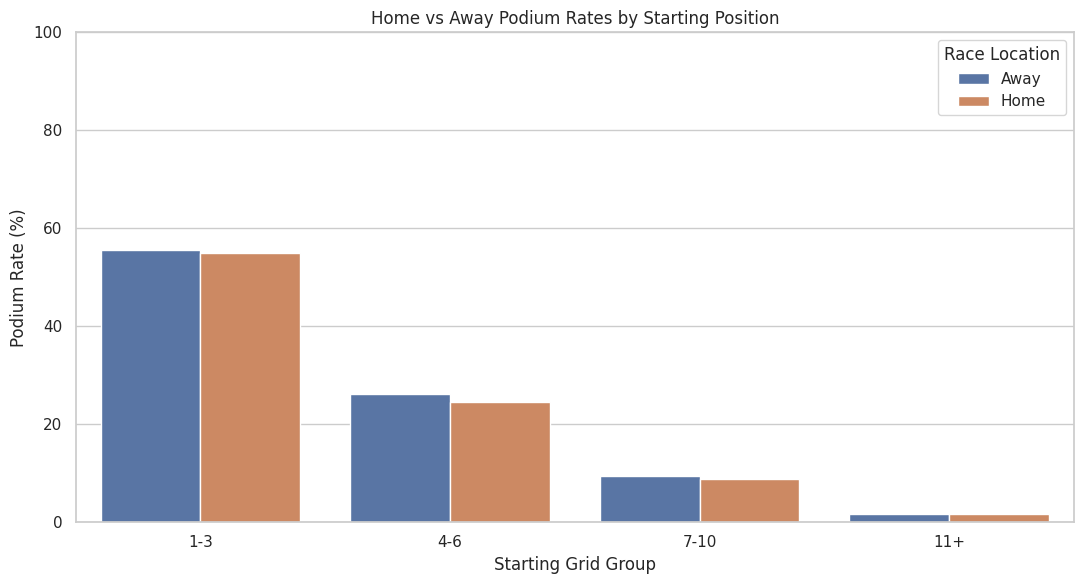

In [37]:

plt.figure(figsize=(11, 6))

sns.barplot(
    data=home_results,
    x="grid_group",
    y="podium_rate",
    hue="race_location",
    hue_order=["Away", "Home"]
)

plt.title(
    "Home vs Away Podium Rates by Starting Position"
)

plt.xlabel("Starting Grid Group")
plt.ylabel("Podium Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Race Location")
plt.tight_layout()
plt.show()


In [38]:

home_comparison = home_results.pivot(
    index="grid_group",
    columns="race_location",
    values="podium_rate"
)

home_comparison["Home Advantage (pp)"] = (
    home_comparison["Home"]
    - home_comparison["Away"]
)

display(home_comparison)


race_location,Away,Home,Home Advantage (pp)
grid_group,,,
1-3,55.537669,54.924242,-0.613427
4-6,26.102350,24.521073,-1.581277
7-10,9.340126,8.785530,-0.554596
11+,1.676249,1.633523,-0.042726


In [39]:

# Keep grid groups observed in both locations
common_rates = home_comparison[
    ["Home", "Away"]
].dropna()

# Use a common starting-position distribution
weights = (
    home_data["grid_group"]
    .value_counts(normalize=True)
    .reindex(common_rates.index)
    .fillna(0)
)

weights = weights / weights.sum()

standardized_rates = (
    common_rates.mul(weights, axis=0)
    .sum(axis=0)
)

print("Grid-standardized podium rates:")
print(standardized_rates)

print(
    "Home minus Away (percentage points):",
    round(
        standardized_rates["Home"]
        - standardized_rates["Away"], 2
    )
)


Grid-standardized podium rates:
race_location
Home    13.188610
Away    13.607801
dtype: float64
Home minus Away (percentage points): -0.42


### Question 2 — Findings and Interpretation

This analysis investigated whether Formula 1 drivers are more likely to achieve podium finishes when racing in their home countries, while controlling for starting position.

Drivers were classified into home and away races using standardized nationality and circuit-country information. To account for the strong influence of starting position, the analysis compared podium rates within four grid groups: 1–3, 4–6, 7–10, and 11+.

The results showed slightly lower home-race podium rates across all four starting-grid groups. Among drivers starting in positions 1–3, the home podium rate was 54.92%, compared with 55.54% away. For positions 4–6, the corresponding rates were 24.52% and 26.10%.

After standardizing for the distribution of starting-grid groups, the overall home podium rate was **13.19%**, compared with **13.61%** for away races, representing a difference of approximately **−0.42 percentage points**.

These findings suggest that the dataset does not demonstrate a substantial home-race podium advantage after accounting for starting position using the selected grid groups.

However, the analysis is observational and does not establish causation or statistical significance. Differences in driver ability, constructor performance, historical racing conditions, and unequal home-versus-away sample sizes may also influence the results. Historical nationality ambiguity and excluded grid-zero records represent additional limitations.

## Question 3: Mechanical Retirement Rates

This analysis compares constructor mechanical-retirement
rates between 2014–2021 and 2022–2024.

Mechanical retirements are identified using documented
race-status classifications.

Only genuine race starts are included in the denominator.

In [40]:

# Select the required years
q3_df = analysis_df[
    analysis_df["year"].between(2014, 2024)
].copy()

# Standardize status labels
q3_df["status_clean"] = (
    q3_df["status_description"]
    .str.strip()
    .str.lower()
)

# Inspect status frequency
status_counts = (
    q3_df["status_description"]
    .value_counts()
    .reset_index()
)

status_counts.columns = [
    "Status", "Number of Records"
]

display(status_counts)

print("Total records:", len(q3_df))
print(
    "Unique statuses:",
    q3_df["status_clean"].nunique()
)


,Status,Number of Records
0,Finished,2403
1,+1 Lap,1178
2,+2 Laps,208
3,Collision,150
4,Accident,85
...,...,...
61,Water pump,1
62,Cooling system,1
63,Fuel pump,1
64,Differential,1


Total records: 4626
Unique statuses: 66


In [41]:

# Examine withdrawals before deciding race-start status
withdrawals = q3_df[
    q3_df["status_clean"].isin(
        ["withdrew", "withdrawn"]
    )
]

display(
    withdrawals[
        ["year", "race_name", "surname",
         "grid", "laps", "status_description"]
    ]
)

# Convert laps to numeric
q3_df["laps_numeric"] = pd.to_numeric(
    q3_df["laps"], errors="coerce"
)

non_start_statuses = {
    "did not start",
    "did not qualify",
    "did not prequalify",
    "did not pre-qualify",
    "withdrawn",
    "107% rule"
}

# Exclude explicit non-starters
is_non_starter = q3_df[
    "status_clean"
].isin(non_start_statuses)

# Treat withdrawals with no recorded laps
# as pre-race withdrawals
is_pre_race_withdrawal = (
    q3_df["status_clean"].eq("withdrew")
    & q3_df["laps_numeric"].fillna(0).eq(0)
)

exclude = is_non_starter | is_pre_race_withdrawal

q3_starts = q3_df.loc[~exclude].copy()

print("Original records:", len(q3_df))
print("Excluded non-starters:", exclude.sum())
print("Candidate race starts:", len(q3_starts))


,year,race_name,surname,grid,laps,status_description
22076,2014,Malaysian Grand Prix,Pérez,14,0,Withdrew
22163,2014,Monaco Grand Prix,Maldonado,15,0,Withdrew
22460,2015,Australian Grand Prix,Bottas,0,0,Withdrew
22461,2015,Australian Grand Prix,Magnussen,17,0,Withdrew
22462,2015,Australian Grand Prix,Kvyat,12,0,Withdrew
23142,2016,Singapore Grand Prix,Grosjean,20,0,Withdrew
23252,2016,Brazilian Grand Prix,Grosjean,7,0,Withdrew
24466,2019,Mexican Grand Prix,Norris,8,48,Withdrew
24796,2020,Turkish Grand Prix,Magnussen,13,55,Withdrew
25347,2022,Saudi Arabian Grand Prix,Schumacher,0,0,Withdrew


Original records: 4626
Excluded non-starters: 11
Candidate race starts: 4615


In [42]:

mechanical_statuses = {
    "engine", "gearbox", "transmission",
    "clutch", "hydraulics", "electrical",
    "electronics", "brakes", "suspension",
    "differential", "overheating",
    "radiator", "alternator", "fuel system",
    "fuel pump", "oil leak", "oil pressure",
    "water leak", "water pressure",
    "power unit", "turbo", "driveshaft",
    "steering", "throttle", "exhaust",
    "ignition", "battery", "pneumatics",

    # Additional statuses from your output
    "power loss", "mechanical", "ers",
    "fuel pressure", "drivetrain",
    "spark plugs", "fuel leak",
    "cooling system", "water pump"
}

non_mechanical_statuses = {
    "finished", "accident", "collision",
    "collision damage", "spun off",
    "disqualified", "puncture", "tyre",
    "tyre puncture",

    # Additional non-mechanical outcomes
    "illness", "excluded", "debris",
    "out of fuel", "withdrew"
}

# Insufficient information to establish cause
unknown_statuses = {
    "retired", "wheel", "undertray",
    "rear wing", "front wing", "wheel nut",
    "technical", "damage", "vibrations",
    "seat", "brake duct"
}

s = q3_starts["status_clean"]

is_mechanical = s.isin(mechanical_statuses)

is_non_mechanical = (
    s.isin(non_mechanical_statuses)
    | s.str.fullmatch(r"\+\d+ laps?", na=False)
)

is_unknown = s.isin(unknown_statuses)

q3_starts["retirement_category"] = np.select(
    [
        is_mechanical,
        is_non_mechanical,
        is_unknown
    ],
    [
        "Mechanical",
        "Non-mechanical",
        "Unknown"
    ],
    default="REVIEW"
)

print("Classification summary:")
display(
    q3_starts["retirement_category"]
    .value_counts()
)

print("\nStill requiring review:")
display(
    q3_starts.loc[
        q3_starts["retirement_category"] == "REVIEW",
        "status_description"
    ].value_counts()
)

print("\nAmbiguous causes:")
display(
    q3_starts.loc[
        q3_starts["retirement_category"] == "Unknown",
        "status_description"
    ].value_counts()
)
# Reclassify withdrawals after recorded racing laps
late_withdrawal = (
    q3_starts["status_clean"].eq("withdrew")
    & q3_starts["laps_numeric"].gt(0)
)

q3_starts.loc[
    late_withdrawal,
    "retirement_category"
] = "Unknown"

print(
    q3_starts["retirement_category"].value_counts()
)



Classification summary:


retirement_category
Non-mechanical    4161
Mechanical         372
Unknown             82
Name: count, dtype: int64


Still requiring review:


Series([], Name: count, dtype: int64)


Ambiguous causes:


status_description
Retired       50
Wheel         11
Undertray      4
Wheel nut      3
Rear wing      3
Front wing     3
Technical      2
Damage         2
Vibrations     2
Brake duct     1
Seat           1
Name: count, dtype: int64

retirement_category
Non-mechanical    4158
Mechanical         372
Unknown             85
Name: count, dtype: int64


In [43]:

# Stop if the status classification is incomplete
assert not (
    q3_starts["retirement_category"] == "REVIEW"
).any(), (
    "Review and classify all remaining statuses "
    "before calculating retirement rates."
)

q3_starts["era"] = np.where(
    q3_starts["year"] <= 2021,
    "2014-2021",
    "2022-2024"
)

q3_starts["mechanical_retirement"] = (
    q3_starts["retirement_category"]
    == "Mechanical"
).astype(int)

mechanical_results = (
    q3_starts.groupby(
        ["era", "constructor_name"]
    )
    .agg(
        race_starts=("raceId", "size"),
        mechanical_retirements=(
            "mechanical_retirement", "sum"
        )
    )
    .reset_index()
)

mechanical_results["retirement_rate"] = (
    mechanical_results["mechanical_retirements"]
    / mechanical_results["race_starts"]
    * 100
)

display(
    mechanical_results.sort_values(
        ["era", "retirement_rate"],
        ascending=[True, False]
    )
)

,era,constructor_name,race_starts,mechanical_retirements,retirement_rate
4,2014-2021,Caterham,34,8,23.529412
8,2014-2021,Lotus F1,75,13,17.333333
17,2014-2021,Toro Rosso,242,39,16.115702
15,2014-2021,Renault,200,27,13.500000
11,2014-2021,McLaren,319,43,13.479624
16,2014-2021,Sauber,200,22,11.000000
14,2014-2021,Red Bull,319,33,10.344828
1,2014-2021,AlphaTauri,78,8,10.256410
10,2014-2021,Marussia,31,3,9.677419
13,2014-2021,Racing Point,76,7,9.210526


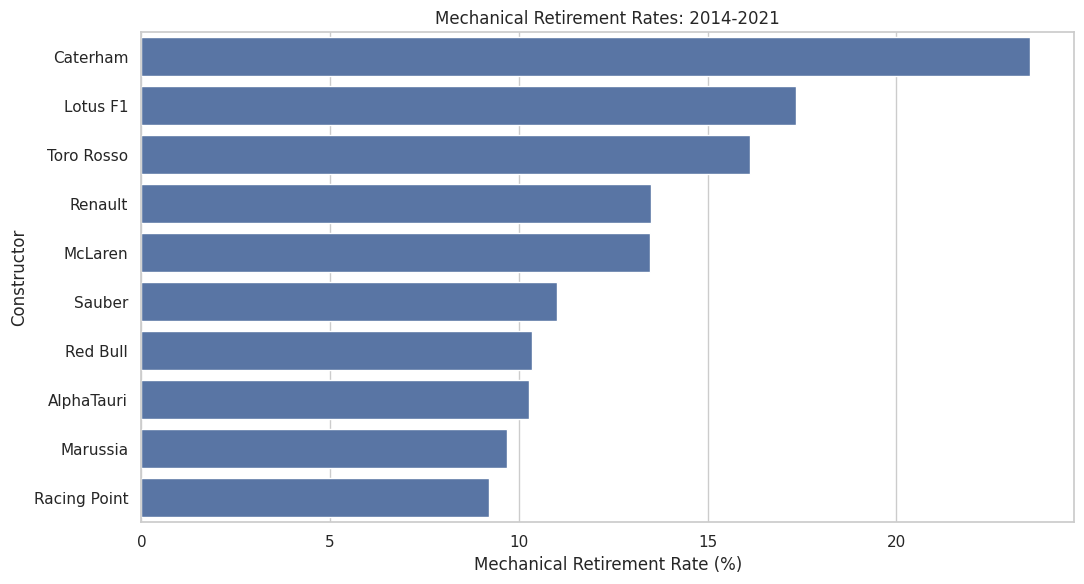

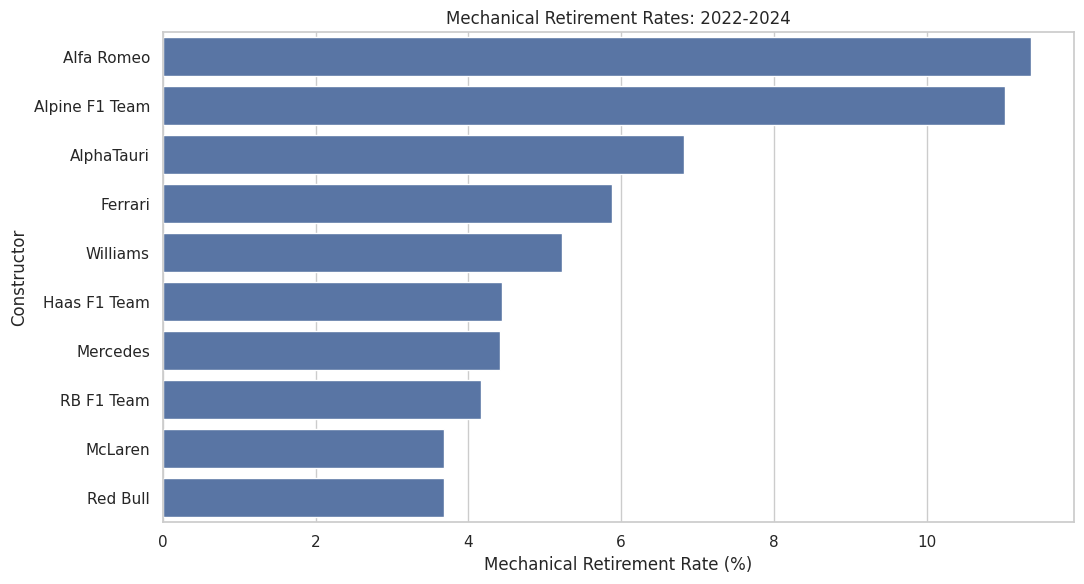

In [44]:

for era in ["2014-2021", "2022-2024"]:

    era_data = mechanical_results[
        mechanical_results["era"] == era
    ]

    # Exclude extremely small samples
    era_data = era_data[
        era_data["race_starts"] >= 20
    ]

    top_10 = era_data.nlargest(
        10, "retirement_rate"
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=top_10,
        x="retirement_rate",
        y="constructor_name"
    )

    plt.title(
        f"Mechanical Retirement Rates: {era}"
    )
    plt.xlabel("Mechanical Retirement Rate (%)")
    plt.ylabel("Constructor")
    plt.tight_layout()
    plt.show()


In [45]:

assert q3_starts[
    "retirement_category"
].ne("REVIEW").all()

assert mechanical_results[
    "retirement_rate"
].between(0, 100).all()

print("Validation passed.")

display(
    mechanical_results.sort_values(
        "retirement_rate",
        ascending=False
    ).head(10)
)


Validation passed.


,era,constructor_name,race_starts,mechanical_retirements,retirement_rate
4,2014-2021,Caterham,34,8,23.529412
8,2014-2021,Lotus F1,75,13,17.333333
17,2014-2021,Toro Rosso,242,39,16.115702
15,2014-2021,Renault,200,27,13.500000
11,2014-2021,McLaren,319,43,13.479624
19,2022-2024,Alfa Romeo,88,10,11.363636
21,2022-2024,Alpine F1 Team,136,15,11.029412
16,2014-2021,Sauber,200,22,11.000000
14,2014-2021,Red Bull,319,33,10.344828
1,2014-2021,AlphaTauri,78,8,10.256410


### Question 3 — Findings and Interpretation

This analysis investigated which Formula 1 constructors experienced the highest mechanical-retirement rates across two periods: 2014–2021 and 2022–2024.

Mechanical retirements were identified by classifying race-ending statuses such as engine, gearbox, hydraulics, and electrical failures. Accidents, collisions, and other non-mechanical outcomes were excluded from the mechanical-failure count.

**2014–2021 Results**

Caterham recorded the highest confirmed mechanical-retirement rate at **23.53%** (8 retirements from 34 starts), followed by Lotus F1 at **17.33%** and Toro Rosso at **16.12%**. Renault and McLaren also recorded relatively high rates of 13.50% and 13.48%, respectively.

**2022–2024 Results**

Alfa Romeo recorded the highest confirmed mechanical-retirement rate at **11.36%**, followed closely by Alpine F1 Team at **11.03%**. AlphaTauri recorded 6.82%, Ferrari 5.88%, and Williams 5.22%.

**Comparison Between Eras**

The overall confirmed mechanical-retirement rate decreased from **9.11%** during 2014–2021 to **5.54%** during 2022–2024, representing a reduction of approximately **3.57 percentage points**.

These results indicate a lower observed frequency of confirmed mechanical retirements in the more recent period. However, this does not establish that the 2022 technical regulations caused the decrease.

**Limitations**

The analysis classified 85 records as having unknown or ambiguous retirement causes. These records remained in the race-start denominator but were not counted as confirmed mechanical retirements. Therefore, the reported rates represent conservative estimates under the adopted classification policy.

Additional limitations include differences in constructor participation, team name changes, and unequal sample sizes between the two periods.

In [46]:

# Step 6: Feature Engineering

model_df = analysis_df.sort_values(
    ["year", "round", "raceId", "driverId"]
).copy()

# Previous 5 driver-race records only
model_df["driver_form5"] = (
    model_df.groupby("driverId")["podium"]
    .transform(
        lambda s: s.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)

display(
    model_df[
        ["year", "driverId", "podium", "driver_form5"]
    ].head(15)
)


,year,driverId,podium,driver_form5
20532,1950,579,0,NaN
20533,1950,589,0,NaN
20534,1950,619,0,NaN
20535,1950,627,0,NaN
20536,1950,640,0,NaN
20537,1950,642,1,NaN
20538,1950,660,0,NaN
20539,1950,661,0,NaN
20540,1950,666,0,NaN
20541,1950,669,0,NaN


In [47]:

team_races = (
    model_df.groupby(
        ["constructorId", "raceId"],
        as_index=False
    )
    .agg(
        year=("year", "first"),
        round=("round", "first"),
        team_podium_rate=("podium", "mean")
    )
)

team_races = team_races.sort_values(
    ["constructorId", "year", "round", "raceId"]
)

team_races["constructor_form5"] = (
    team_races.groupby("constructorId")[
        "team_podium_rate"
    ].transform(
        lambda s: s.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)

model_df = model_df.merge(
    team_races[
        ["constructorId", "raceId",
         "constructor_form5"]
    ],
    on=["constructorId", "raceId"],
    how="left",
    validate="many_to_one"
)

display(
    model_df[
        ["year", "constructor_name",
         "podium", "constructor_form5"]
    ].head(15)
)


,year,constructor_name,podium,constructor_form5
0,1950,Alfa Romeo,0,NaN
1,1950,Maserati,0,NaN
2,1950,ERA,0,NaN
3,1950,Talbot-Lago,0,NaN
4,1950,Maserati,0,NaN
5,1950,Alfa Romeo,1,NaN
6,1950,Talbot-Lago,0,NaN
7,1950,ERA,0,NaN
8,1950,ERA,0,NaN
9,1950,Maserati,0,NaN


In [48]:

assert not model_df.duplicated(
    ["raceId", "driverId"]
).any()

assert model_df["driver_form5"].dropna().between(
    0, 1
).all()

assert model_df["constructor_form5"].dropna().between(
    0, 1
).all()

print("Feature validation passed!")

print("\nMissing driver form values:")
print(model_df["driver_form5"].isna().sum())

print("\nMissing constructor form values:")
print(model_df["constructor_form5"].isna().sum())


Feature validation passed!

Missing driver form values:
861

Missing constructor form values:
346


## 6.4 Pre-Race Championship Standings

Driver and constructor championship standings are
used as predictive features.

Since standings are recorded after each race,
they are shifted within each season to ensure
only information available before the current
race is used.

In [49]:

def create_pre_race_standings(
    table_name, entity_col, prefix
):
    standings = cleaned_tables[table_name].copy()

    # Add season and round information
    standings = standings.merge(
        cleaned_tables["races"][
            ["raceId", "year", "round"]
        ],
        on="raceId",
        how="left",
        validate="many_to_one"
    )

    # Sort in chronological order
    standings = standings.sort_values(
        ["year", "round", "raceId"]
    )

    # Group by season and driver/constructor
    grouped = standings.groupby(
        ["year", entity_col]
    )

    # Previous known standings only
    standings[f"{prefix}_points_pre"] = (
        grouped["points"].shift(1)
    )

    standings[f"{prefix}_rank_pre"] = (
        grouped["position"].shift(1)
    )

    return standings[
        [
            "raceId",
            entity_col,
            f"{prefix}_points_pre",
            f"{prefix}_rank_pre"
        ]
    ]


In [50]:

driver_pre = create_pre_race_standings(
    table_name="driver_standings",
    entity_col="driverId",
    prefix="driver"
)

model_df = model_df.merge(
    driver_pre,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

display(
    model_df[
        [
            "year", "round",
            "surname",
            "driver_points_pre",
            "driver_rank_pre"
        ]
    ].head(20)
)


,year,round,surname,driver_points_pre,driver_rank_pre
0,1950,1,Fangio,NaN,NaN
1,1950,1,Chiron,NaN,NaN
2,1950,1,Gerard,NaN,NaN
3,1950,1,Rosier,NaN,NaN
4,1950,1,de Graffenried,NaN,NaN
5,1950,1,Farina,NaN,NaN
6,1950,1,Claes,NaN,NaN
7,1950,1,Walker,NaN,NaN
8,1950,1,Rolt,NaN,NaN
9,1950,1,Bira,NaN,NaN


In [51]:

constructor_pre = create_pre_race_standings(
    table_name="constructor_standings",
    entity_col="constructorId",
    prefix="constructor"
)

model_df = model_df.merge(
    constructor_pre,
    on=["raceId", "constructorId"],
    how="left",
    validate="many_to_one"
)

display(
    model_df[
        [
            "year", "round",
            "constructor_name",
            "constructor_points_pre",
            "constructor_rank_pre"
        ]
    ].head(20)
)


,year,round,constructor_name,constructor_points_pre,constructor_rank_pre
0,1950,1,Alfa Romeo,NaN,NaN
1,1950,1,Maserati,NaN,NaN
2,1950,1,ERA,NaN,NaN
3,1950,1,Talbot-Lago,NaN,NaN
4,1950,1,Maserati,NaN,NaN
5,1950,1,Alfa Romeo,NaN,NaN
6,1950,1,Talbot-Lago,NaN,NaN
7,1950,1,ERA,NaN,NaN
8,1950,1,ERA,NaN,NaN
9,1950,1,Maserati,NaN,NaN


In [52]:

# Ensure no additional records appeared
assert len(model_df) == len(analysis_df)

# Verify required grain
assert not model_df.duplicated(
    ["raceId", "driverId"]
).any()

# First round should not inherit
# standings from the previous season
first_round = model_df["round"] == 1

assert model_df.loc[
    first_round, "driver_points_pre"
].isna().all()

assert model_df.loc[
    first_round, "constructor_points_pre"
].isna().all()

print("Pre-race standings validation passed!")

print("\nMissing values:")
print(
    model_df[
        [
            "driver_points_pre",
            "driver_rank_pre",
            "constructor_points_pre",
            "constructor_rank_pre"
        ]
    ].isna().sum()
)


Pre-race standings validation passed!

Missing values:
driver_points_pre         3661
driver_rank_pre           3661
constructor_points_pre    3525
constructor_rank_pre      3525
dtype: int64


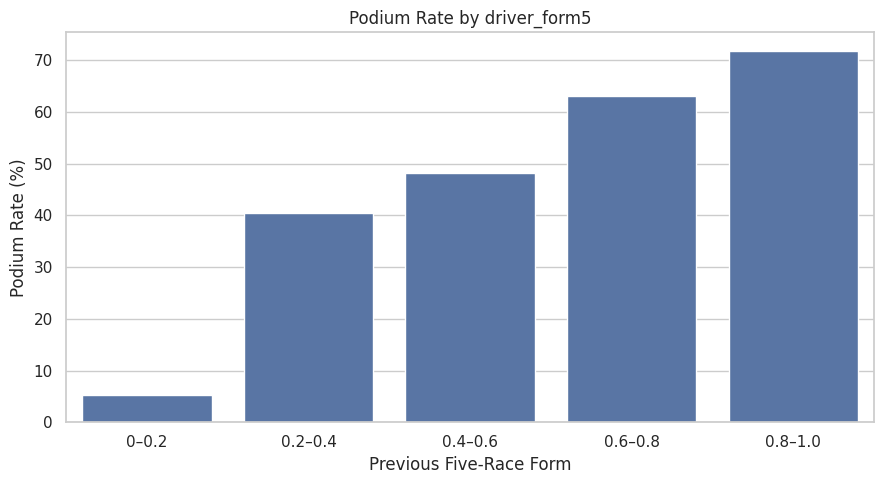

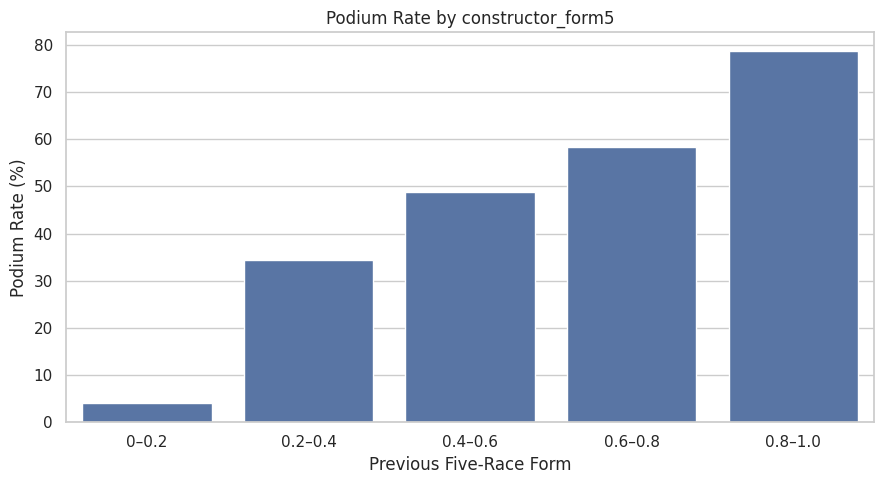

In [53]:

form_eda = model_df[
    model_df["year"].between(2006, 2019)
].copy()

for feature in [
    "driver_form5",
    "constructor_form5"
]:
    temp = form_eda.dropna(
        subset=[feature]
    ).copy()

    temp["form_group"] = pd.cut(
        temp[feature],
        bins=[-0.001, 0.2, 0.4, 0.6, 0.8, 1.0],
        labels=[
            "0–0.2",
            "0.2–0.4",
            "0.4–0.6",
            "0.6–0.8",
            "0.8–1.0"
        ]
    )

    rates = (
        temp.groupby(
            "form_group",
            observed=True
        )["podium"]
        .mean()
        .mul(100)
        .reset_index(name="podium_rate")
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=rates,
        x="form_group",
        y="podium_rate"
    )

    plt.title(
        f"Podium Rate by {feature}"
    )
    plt.xlabel("Previous Five-Race Form")
    plt.ylabel("Podium Rate (%)")
    plt.tight_layout()
    plt.show()


### Feature Engineering — EDA Findings

The exploratory analysis examined the relationship between historical performance and podium-finishing probability during the 2006–2019 training period.

**Driver Form:** The analysis shows a strong positive association between a driver's previous five-entry podium rate and their probability of finishing on the podium in the current race. Drivers with stronger recent results consistently achieved higher podium rates.

**Constructor Form:** A similar positive relationship was observed for constructor performance. Drivers representing teams with higher recent podium rates were substantially more likely to achieve podium finishes.

These findings support including `driver_form5` and `constructor_form5` as predictive features.

Both features were calculated using previous race records only, with a one-race shift to prevent current-race target leakage. The observed relationships are predictive associations rather than causal effects.

# 7. Feature Selection and Dataset Splitting

We select pre-race information to predict podium
finishes and split the dataset chronologically
to avoid future-data leakage.

In [54]:

# Modeling period
data = model_df[
    model_df["year"].between(2006, 2024)
].copy()

# Starting grid 0 is not an ordinary grid rank
data["grid_position"] = data["grid"].where(
    data["grid"] > 0, np.nan
)

data["grid_zero_flag"] = (
    data["grid"] == 0
).astype(int)

data["qualifying_position"] = pd.to_numeric(
    data["qualifying_position"],
    errors="coerce"
)

# Numerical features
numeric_features = [
    "year",
    "round",
    "grid_position",
    "grid_zero_flag",
    "qualifying_position",
    "driver_form5",
    "constructor_form5",
    "driver_points_pre",
    "driver_rank_pre",
    "constructor_points_pre",
    "constructor_rank_pre"
]

# Categorical features
categorical_features = [
    "constructorId",
    "circuitId"
]

features = numeric_features + categorical_features
target = "podium"

X = data[features].copy()
y = data[target].copy()

print("Number of records:", len(data))
print("Number of input features:", len(features))

display(X.head())


Number of records: 7914
Number of input features: 13


,year,round,grid_position,grid_zero_flag,qualifying_position,driver_form5,constructor_form5,driver_points_pre,driver_rank_pre,constructor_points_pre,constructor_rank_pre,constructorId,circuitId
18754,2006,1,10.0,0,10.0,0.0,NaN,NaN,NaN,NaN,NaN,2,3
18755,2006,1,12.0,0,12.0,NaN,0.0,NaN,NaN,NaN,NaN,3,3
18756,2006,1,4.0,0,4.0,1.0,0.7,NaN,NaN,NaN,NaN,4,3
18757,2006,1,22.0,0,22.0,0.8,0.6,NaN,NaN,NaN,NaN,1,3
18758,2006,1,20.0,0,20.0,0.0,NaN,NaN,NaN,NaN,NaN,8,3


In [55]:

train_df = data[
    data["year"] <= 2019
].copy()

val_df = data[
    data["year"].between(2020, 2021)
].copy()

test_df = data[
    data["year"].between(2022, 2024)
].copy()

X_train = train_df[features].copy()
y_train = train_df[target].copy()

X_val = val_df[features].copy()
y_val = val_df[target].copy()

X_test = test_df[features].copy()
y_test = test_df[target].copy()

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Rows": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Podium Rate (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary)


,Dataset,Rows,Podium Rate (%)
0,Training,5775,13.922078
1,Validation,780,15.000000
2,Testing,1359,15.011038


,Training (%),Validation (%),Testing (%)
year,0.00,0.00,0.00
round,0.00,0.00,0.00
grid_position,0.50,2.18,2.94
grid_zero_flag,0.00,0.00,0.00
qualifying_position,0.40,0.13,0.00
driver_form5,1.02,0.77,0.59
constructor_form5,0.59,0.51,0.15
driver_points_pre,6.72,5.64,5.00
driver_rank_pre,6.72,5.64,5.00
constructor_points_pre,5.61,5.13,4.42


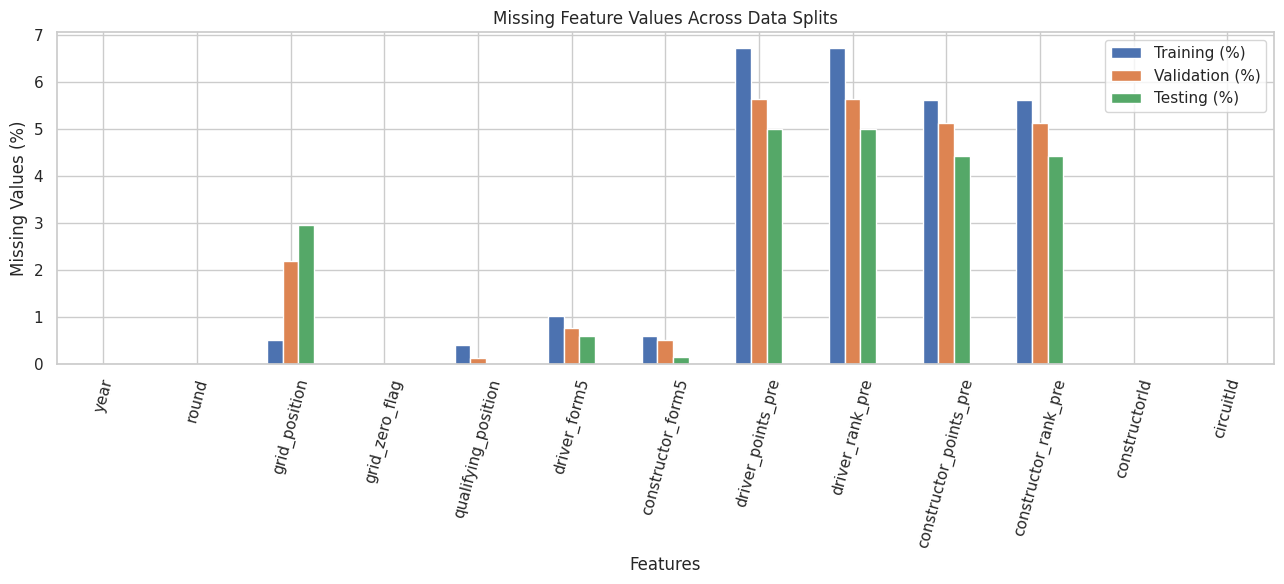

In [56]:

missing_summary = pd.DataFrame({
    "Training (%)": X_train.isna().mean() * 100,
    "Validation (%)": X_val.isna().mean() * 100,
    "Testing (%)": X_test.isna().mean() * 100
})

display(missing_summary.round(2))

missing_summary.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Missing Feature Values Across Data Splits")
plt.ylabel("Missing Values (%)")
plt.xlabel("Features")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


In [57]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median"
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


In [58]:

# Verify chronological separation
assert train_df["year"].max() < val_df["year"].min()
assert val_df["year"].max() < test_df["year"].min()

# Verify row counts
assert (
    len(train_df) + len(val_df) + len(test_df)
    == len(data)
)

# Verify no race appears in multiple splits
assert set(train_df["raceId"]).isdisjoint(
    set(val_df["raceId"])
)

assert set(val_df["raceId"]).isdisjoint(
    set(test_df["raceId"])
)

# Verify the target is binary
assert set(y.unique()).issubset({0, 1})

# Verify no explicit post-race features selected
forbidden_features = {
    "positionOrder",
    "points",
    "statusId",
    "status_description",
    "milliseconds",
    "laps",
    "fastestLap",
    "fastestLapTime"
}

assert not forbidden_features.intersection(features)

print("All dataset-splitting checks passed!")


All dataset-splitting checks passed!


### Dataset Splitting and Preprocessing Justification

The dataset was divided chronologically into training (2006–2019), validation (2020–2021), and testing (2022–2024).

A chronological split was selected because Formula 1 results form a time-dependent dataset. This approach ensures the models are evaluated on later races rather than randomly mixing historical and future observations.

The modeling period begins in 2006 because qualifying data is more consistently available in the modern Formula 1 era.

Numerical features will undergo median imputation and standardization, while categorical identifiers will be encoded using one-hot encoding.

All preprocessing transformations will be fitted exclusively on training data to prevent information leakage from the validation and test sets.

# 8. Predictive Modeling

We train and compare three binary classification models:
Logistic Regression, Random Forest, and a shallow
feedforward neural network.

All models use the same training data and feature set.
Preprocessing is fitted exclusively on training data.

In [59]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

RANDOM_STATE = 42

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Shallow Neural Network": MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=400,
        early_stopping=True,
        random_state=RANDOM_STATE
    )
}

print("Models initialized successfully!")


Models initialized successfully!


In [60]:

fitted_models = {}

for name, estimator in models.items():

    print(f"\nTraining: {name}")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(estimator))
    ])

    pipeline.fit(X_train, y_train)

    fitted_models[name] = pipeline

    print(f"{name}: Training completed!")

print("\nAll three models trained successfully!")



Training: Logistic Regression
Logistic Regression: Training completed!

Training: Random Forest
Random Forest: Training completed!

Training: Shallow Neural Network
Shallow Neural Network: Training completed!

All three models trained successfully!


In [61]:

from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    auc,
    f1_score,
    precision_score,
    recall_score
)

def evaluate_model(pipeline, X_data, y_data):
    probabilities = pipeline.predict_proba(
        X_data
    )[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_data, probabilities
        )
    )

    return {
        "ROC-AUC": roc_auc_score(
            y_data, probabilities
        ),
        "PR-AUC": auc(
            recall_curve, precision_curve
        ),
        "F1": f1_score(
            y_data, predictions
        ),
        "Precision": precision_score(
            y_data, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_data, predictions,
            zero_division=0
        )
    }

model_results = []

for name, pipeline in fitted_models.items():

    for split_name, X_data, y_data in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val)
    ]:

        scores = evaluate_model(
            pipeline, X_data, y_data
        )

        model_results.append({
            "Model": name,
            "Dataset": split_name,
            **scores
        })

results_df = pd.DataFrame(model_results)

display(results_df.round(4))


,Model,Dataset,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Training,0.9354,0.6728,0.6263,0.4783,0.9067
1,Logistic Regression,Validation,0.9237,0.6949,0.6763,0.5839,0.8034
2,Random Forest,Training,0.9831,0.9054,0.7654,0.6430,0.9453
3,Random Forest,Validation,0.9264,0.7013,0.6873,0.6268,0.7607
4,Shallow Neural Network,Training,0.9413,0.7025,0.6641,0.6838,0.6455
5,Shallow Neural Network,Validation,0.9210,0.7184,0.6294,0.7750,0.5299


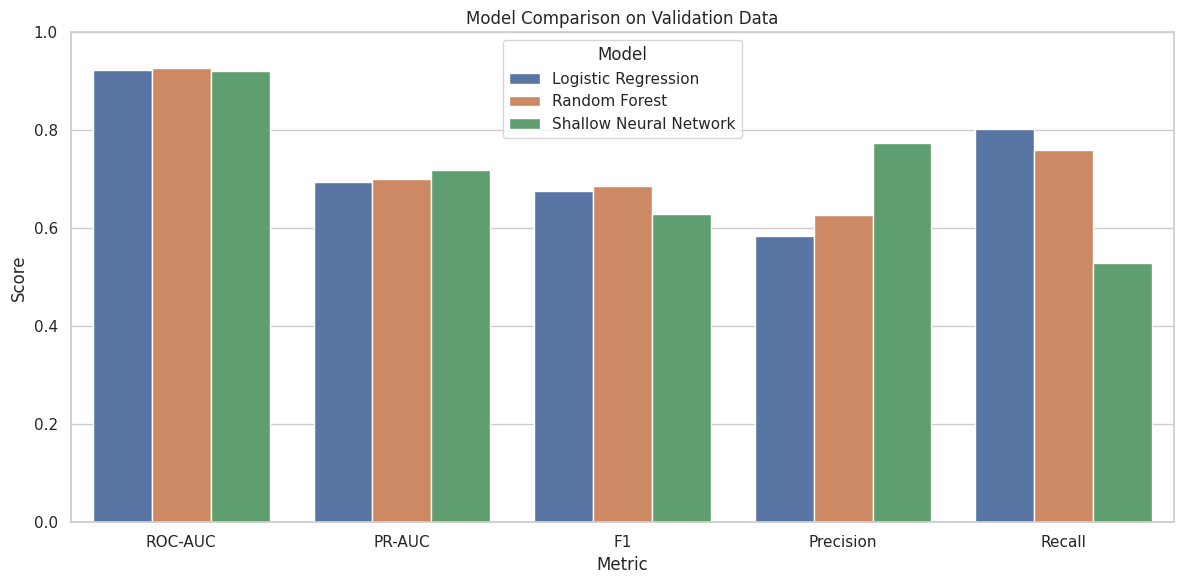

In [62]:

validation_results = results_df[
    results_df["Dataset"] == "Validation"
].copy()

metrics = [
    "ROC-AUC", "PR-AUC", "F1",
    "Precision", "Recall"
]

plot_data = validation_results.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Comparison on Validation Data")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


In [63]:

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

threshold_results = []
best_thresholds = {}

for name, pipeline in fitted_models.items():

    probabilities = pipeline.predict_proba(
        X_val
    )[:, 1]

    # Try thresholds between 0.05 and 0.95
    thresholds = np.linspace(0.05, 0.95, 91)

    best_f1 = -1
    best_threshold = 0.5

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        score = f1_score(
            y_val, predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    best_thresholds[name] = best_threshold

    final_predictions = (
        probabilities >= best_threshold
    ).astype(int)

    threshold_results.append({
        "Model": name,
        "Best Threshold": best_threshold,
        "Validation F1": best_f1,
        "Precision": precision_score(
            y_val, final_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, final_predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Model,Best Threshold,Validation F1,Precision,Recall
0,Logistic Regression,0.68,0.7078,0.6825,0.7350
1,Random Forest,0.54,0.7040,0.6617,0.7521
2,Shallow Neural Network,0.27,0.6914,0.6667,0.7179


# 9. Threshold Optimization and Model Evaluation

Classification thresholds are optimized using validation
data only, maximizing the F1-score.

The test set remains untouched during model selection.

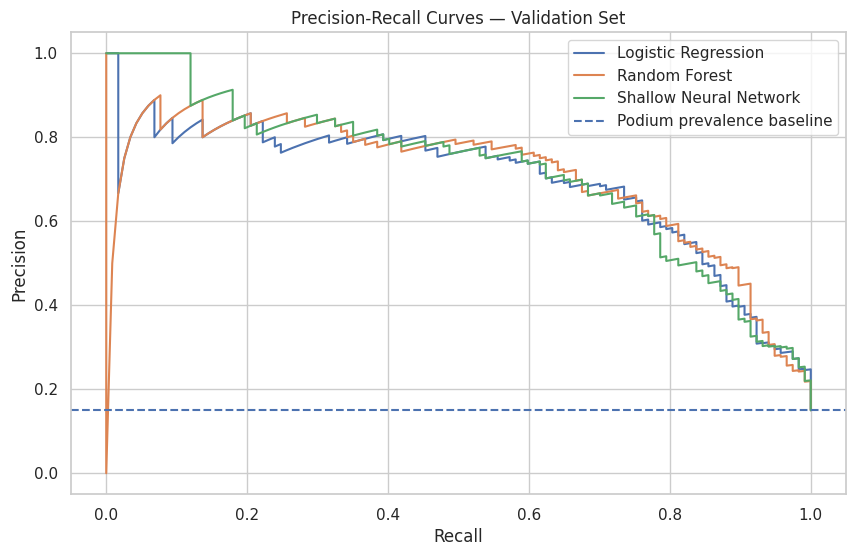

In [64]:

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10, 6))

for name, pipeline in fitted_models.items():

    probabilities = pipeline.predict_proba(
        X_val
    )[:, 1]

    precision, recall, _ = (
        precision_recall_curve(
            y_val, probabilities
        )
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.axhline(
    y_val.mean(),
    linestyle="--",
    label="Podium prevalence baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Validation Set")
plt.legend()
plt.grid(True)
plt.show()


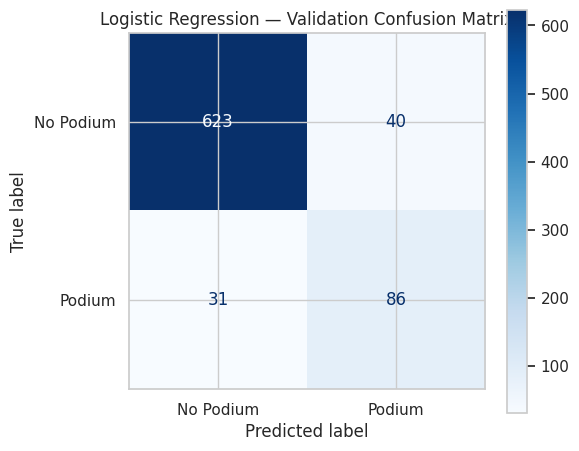

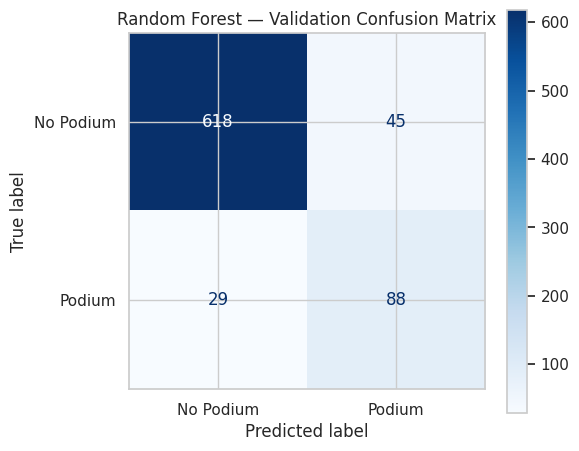

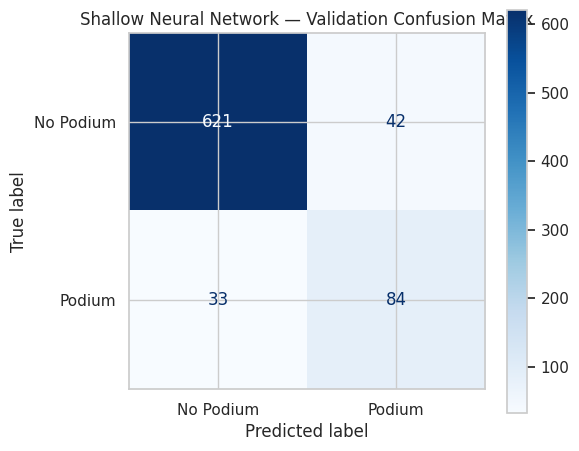

In [65]:

from sklearn.metrics import ConfusionMatrixDisplay

for name, pipeline in fitted_models.items():

    probabilities = pipeline.predict_proba(
        X_val
    )[:, 1]

    predictions = (
        probabilities >= best_thresholds[name]
    ).astype(int)

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        display_labels=["No Podium", "Podium"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(
        f"{name} — Validation Confusion Matrix"
    )

    plt.tight_layout()
    plt.show()


In [66]:

# Combine original ranking metrics
# with optimized classification metrics
final_validation = threshold_df.merge(
    validation_results[
        ["Model", "ROC-AUC", "PR-AUC"]
    ],
    on="Model"
)

final_validation = final_validation.sort_values(
    "PR-AUC",
    ascending=False
)

display(final_validation.round(4))

print(
    "Leading model by validation PR-AUC:",
    final_validation.iloc[0]["Model"]
)


,Model,Best Threshold,Validation F1,Precision,Recall,ROC-AUC,PR-AUC
2,Shallow Neural Network,0.27,0.6914,0.6667,0.7179,0.9210,0.7184
1,Random Forest,0.54,0.7040,0.6617,0.7521,0.9264,0.7013
0,Logistic Regression,0.68,0.7078,0.6825,0.7350,0.9237,0.6949


Leading model by validation PR-AUC: Shallow Neural Network


In [67]:

# 10. Hyperparameter Experiments

from sklearn.base import clone

experiment_models = {
    "Logistic Baseline": clone(
        models["Logistic Regression"]
    ),

    "RF Baseline": clone(
        models["Random Forest"]
    ),

    "RF Depth 10": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "RF Depth 6": RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "NN Baseline": clone(
        models["Shallow Neural Network"]
    ),

    "NN Smaller": MLPClassifier(
        hidden_layer_sizes=(16,),
        alpha=0.01,
        max_iter=400,
        early_stopping=True,
        random_state=42
    ),

    "NN Wider": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        alpha=0.01,
        max_iter=400,
        early_stopping=True,
        random_state=42
    )
}

experiment_fitted = {}
experiment_results = []

for name, estimator in experiment_models.items():

    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(estimator))
    ])

    pipeline.fit(X_train, y_train)
    experiment_fitted[name] = pipeline

    for split_name, X_part, y_part in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val)
    ]:

        scores = evaluate_model(
            pipeline, X_part, y_part
        )

        experiment_results.append({
            "Experiment": name,
            "Dataset": split_name,
            **scores
        })

experiment_df = pd.DataFrame(
    experiment_results
)

display(experiment_df.round(4))


Training: Logistic Baseline
Training: RF Baseline
Training: RF Depth 10
Training: RF Depth 6
Training: NN Baseline
Training: NN Smaller
Training: NN Wider


,Experiment,Dataset,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Baseline,Training,0.9354,0.6728,0.6263,0.4783,0.9067
1,Logistic Baseline,Validation,0.9237,0.6949,0.6763,0.5839,0.8034
2,RF Baseline,Training,0.9831,0.9054,0.7654,0.6430,0.9453
3,RF Baseline,Validation,0.9264,0.7013,0.6873,0.6268,0.7607
4,RF Depth 10,Training,0.9622,0.7987,0.6951,0.5580,0.9216
5,RF Depth 10,Validation,0.9284,0.7187,0.6713,0.5680,0.8205
6,RF Depth 6,Training,0.9453,0.7202,0.6453,0.4983,0.9154
7,RF Depth 6,Validation,0.9257,0.7186,0.6289,0.4975,0.8547
8,NN Baseline,Training,0.9413,0.7025,0.6641,0.6838,0.6455
9,NN Baseline,Validation,0.9210,0.7184,0.6294,0.7750,0.5299


Dataset,Training,Validation,Overfitting Gap
Experiment,,,
RF Depth 10,0.7987,0.7187,0.0800
RF Depth 6,0.7202,0.7186,0.0016
NN Baseline,0.7025,0.7184,-0.0159
NN Wider,0.7031,0.7127,-0.0096
RF Baseline,0.9054,0.7013,0.2040
Logistic Baseline,0.6728,0.6949,-0.0221
NN Smaller,0.5997,0.6698,-0.0701


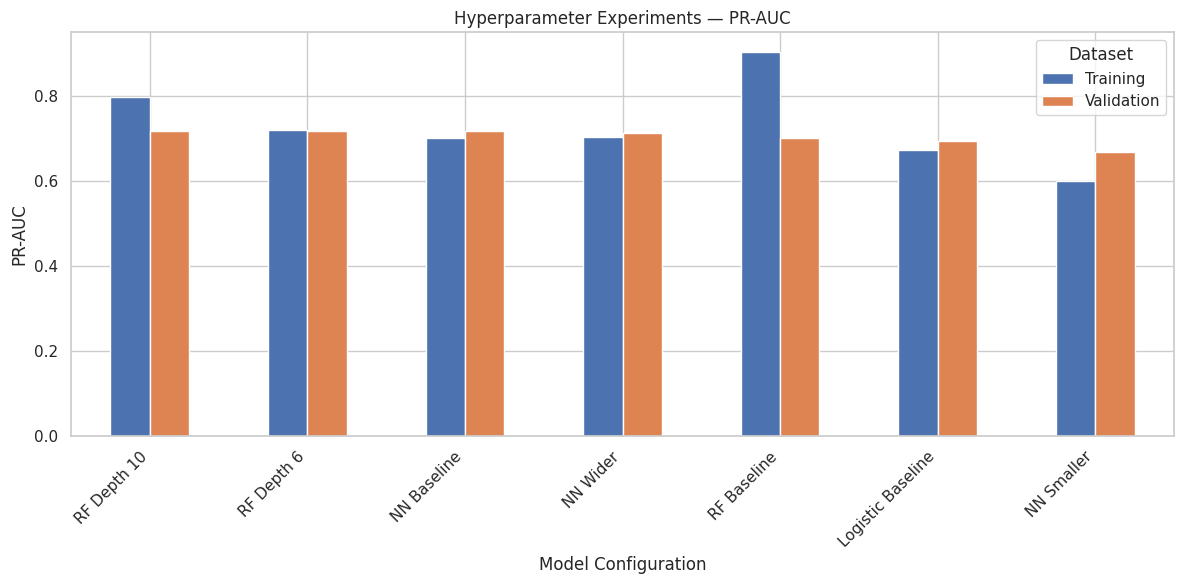

In [68]:

experiment_comparison = experiment_df.pivot(
    index="Experiment",
    columns="Dataset",
    values="PR-AUC"
)

experiment_comparison["Overfitting Gap"] = (
    experiment_comparison["Training"]
    - experiment_comparison["Validation"]
)

experiment_comparison = (
    experiment_comparison.sort_values(
        "Validation", ascending=False
    )
)

display(experiment_comparison.round(4))

experiment_comparison[
    ["Training", "Validation"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Hyperparameter Experiments — PR-AUC"
)
plt.ylabel("PR-AUC")
plt.xlabel("Model Configuration")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [69]:

feature_groups = {
    "All Features": [],
    "Without Grid": [
        "grid_position", "grid_zero_flag"
    ],
    "Without Qualifying": [
        "qualifying_position"
    ],
    "Without Form": [
        "driver_form5", "constructor_form5"
    ],
    "Without Standings": [
        "driver_points_pre", "driver_rank_pre",
        "constructor_points_pre",
        "constructor_rank_pre"
    ]
}

ablation_results = []

for experiment, removed in feature_groups.items():

    selected_numeric = [
        f for f in numeric_features
        if f not in removed
    ]

    selected_categorical = [
        f for f in categorical_features
        if f not in removed
    ]

    selected_features = (
        selected_numeric + selected_categorical
    )

    selected_preprocessor = ColumnTransformer([
        (
            "numeric",
            clone(numeric_pipeline),
            selected_numeric
        ),
        (
            "categorical",
            clone(categorical_pipeline),
            selected_categorical
        )
    ])

    pipeline = Pipeline([
        ("preprocessor", selected_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    pipeline.fit(
        X_train[selected_features],
        y_train
    )

    scores = evaluate_model(
        pipeline,
        X_val[selected_features],
        y_val
    )

    ablation_results.append({
        "Experiment": experiment,
        "PR-AUC": scores["PR-AUC"],
        "ROC-AUC": scores["ROC-AUC"],
        "F1": scores["F1"]
    })

ablation_df = pd.DataFrame(ablation_results)

baseline_prauc = ablation_df.loc[
    ablation_df["Experiment"] == "All Features",
    "PR-AUC"
].iloc[0]

ablation_df["PR-AUC Drop"] = (
    baseline_prauc - ablation_df["PR-AUC"]
)

display(ablation_df.round(4))


,Experiment,PR-AUC,ROC-AUC,F1,PR-AUC Drop
0,All Features,0.6949,0.9237,0.6763,0.0000
1,Without Grid,0.6992,0.9219,0.6667,-0.0043
2,Without Qualifying,0.6914,0.9214,0.6596,0.0035
3,Without Form,0.7030,0.9247,0.6485,-0.0080
4,Without Standings,0.6806,0.9212,0.6490,0.0143


In [70]:

# Step 10.4: Preprocessing-Order Experiments

from sklearn.preprocessing import QuantileTransformer
from sklearn.base import clone

order_experiments = {
    "A1: Impute -> Scale": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]),

    "A2: Scale -> Impute": Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", SimpleImputer(strategy="median"))
    ]),

    "B1: Impute -> Quantile": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("quantile", QuantileTransformer(
            n_quantiles=300,
            output_distribution="normal",
            random_state=42
        ))
    ]),

    "B2: Quantile -> Impute": Pipeline([
        ("quantile", QuantileTransformer(
            n_quantiles=300,
            output_distribution="normal",
            random_state=42
        )),
        ("imputer", SimpleImputer(strategy="median"))
    ])
}

order_results = []

for name, num_pipeline in order_experiments.items():

    print("Running:", name)

    experimental_preprocessor = ColumnTransformer([
        ("numeric", clone(num_pipeline), numeric_features),
        ("categorical", clone(categorical_pipeline),
         categorical_features)
    ])

    experimental_model = Pipeline([
        ("preprocessor", experimental_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    experimental_model.fit(X_train, y_train)

    train_scores = evaluate_model(
        experimental_model, X_train, y_train
    )

    val_scores = evaluate_model(
        experimental_model, X_val, y_val
    )

    order_results.append({
        "Experiment": name,
        "Train PR-AUC": train_scores["PR-AUC"],
        "Validation PR-AUC": val_scores["PR-AUC"],
        "Validation ROC-AUC": val_scores["ROC-AUC"],
        "Validation F1": val_scores["F1"]
    })

order_df = pd.DataFrame(order_results)

display(order_df.round(4))


Running: A1: Impute -> Scale
Running: A2: Scale -> Impute
Running: B1: Impute -> Quantile
Running: B2: Quantile -> Impute


,Experiment,Train PR-AUC,Validation PR-AUC,Validation ROC-AUC,Validation F1
0,A1: Impute -> Scale,0.6728,0.6949,0.9237,0.6763
1,A2: Scale -> Impute,0.6727,0.6952,0.9238,0.6763
2,B1: Impute -> Quantile,0.6786,0.6756,0.9122,0.6129
3,B2: Quantile -> Impute,0.6784,0.6764,0.9122,0.6149


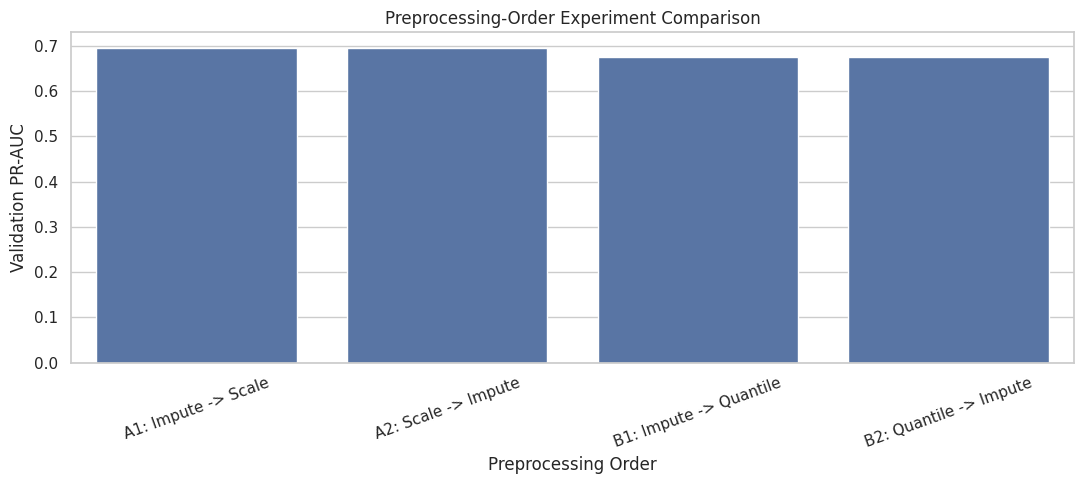

Experiment A:


,Experiment,Train PR-AUC,Validation PR-AUC,Validation ROC-AUC,Validation F1
0,A1: Impute -> Scale,0.672823,0.694921,0.923721,0.676259
1,A2: Scale -> Impute,0.672698,0.695159,0.923812,0.676259


Experiment B:


,Experiment,Train PR-AUC,Validation PR-AUC,Validation ROC-AUC,Validation F1
2,B1: Impute -> Quantile,0.678594,0.675592,0.912171,0.612903
3,B2: Quantile -> Impute,0.678442,0.676380,0.912197,0.614887


In [71]:

plt.figure(figsize=(11, 5))

sns.barplot(
    data=order_df,
    x="Experiment",
    y="Validation PR-AUC"
)

plt.title("Preprocessing-Order Experiment Comparison")
plt.xlabel("Preprocessing Order")
plt.ylabel("Validation PR-AUC")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Compare each pair of orders
experiment_a = order_df.iloc[:2]
experiment_b = order_df.iloc[2:]

print("Experiment A:")
display(experiment_a)

print("Experiment B:")
display(experiment_b)


### 10.4 Preprocessing-Order Experiments — Findings

Two controlled preprocessing-order experiments were conducted using Logistic Regression with identical training and validation datasets.

**Experiment A:** Median imputation followed by standard scaling achieved a validation PR-AUC of 0.6949, while standard scaling followed by median imputation achieved 0.6952. The difference was negligible, suggesting that preprocessing order had little influence on predictive performance in this comparison.

**Experiment B:** Median imputation followed by quantile transformation achieved a validation PR-AUC of 0.6756, compared with 0.6764 when the order was reversed. Again, the order had only a small effect.

Both quantile-based approaches performed worse than the standard-scaling approaches on validation data.

Consequently, the original median-imputation-then-standard-scaling pipeline was retained because of its competitive performance, simplicity, and interpretability.

All preprocessing transformations were fitted on training data only, with validation data used exclusively for evaluation.

# 11. Final Model Selection and Test Evaluation

Random Forest Depth 6 was selected based on
validation PR-AUC, model complexity, and
training-validation generalization.

The final decision was made before evaluating
the unseen 2022–2024 test dataset.

In [72]:

# Select final model
selected_name = "RF Depth 6"
selected_model = experiment_fitted[selected_name]

# Obtain validation probabilities
val_probabilities = selected_model.predict_proba(
    X_val
)[:, 1]

# Search for the best F1 threshold
candidate_thresholds = np.linspace(
    0.05, 0.95, 91
)

threshold_scores = [
    f1_score(
        y_val,
        val_probabilities >= t,
        zero_division=0
    )
    for t in candidate_thresholds
]

best_index = np.argmax(threshold_scores)

selected_threshold = candidate_thresholds[best_index]

print("Selected model:", selected_name)
print("Best threshold:", round(selected_threshold, 3))
print(
    "Optimized Validation F1:",
    round(threshold_scores[best_index], 4)
)


Selected model: RF Depth 6
Best threshold: 0.71
Optimized Validation F1: 0.704


In [73]:

# Original models + selected model
evaluation_models = {
    **fitted_models,
    "RF Depth 6": selected_model
}

# Thresholds determined on validation data only
evaluation_thresholds = {
    **best_thresholds,
    "RF Depth 6": selected_threshold
}

def final_evaluation(model, X_data, y_data, threshold):

    probabilities = model.predict_proba(
        X_data
    )[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_data, probabilities
        )
    )

    return {
        "ROC-AUC": roc_auc_score(
            y_data, probabilities
        ),
        "PR-AUC": auc(
            recall_curve, precision_curve
        ),
        "F1": f1_score(
            y_data, predictions,
            zero_division=0
        ),
        "Precision": precision_score(
            y_data, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_data, predictions,
            zero_division=0
        )
    }

final_results = []

for name, model in evaluation_models.items():

    threshold = evaluation_thresholds[name]

    for split_name, X_part, y_part in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val),
        ("Testing", X_test, y_test)
    ]:

        scores = final_evaluation(
            model, X_part, y_part, threshold
        )

        final_results.append({
            "Model": name,
            "Dataset": split_name,
            "Threshold": threshold,
            **scores
        })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))


,Model,Dataset,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Training,0.68,0.9354,0.6728,0.6663,0.5562,0.8308
1,Logistic Regression,Validation,0.68,0.9237,0.6949,0.7078,0.6825,0.7350
2,Logistic Regression,Testing,0.68,0.9346,0.6934,0.6546,0.6067,0.7108
3,Random Forest,Training,0.54,0.9831,0.9054,0.7787,0.6709,0.9279
4,Random Forest,Validation,0.54,0.9264,0.7013,0.7040,0.6617,0.7521
5,Random Forest,Testing,0.54,0.9353,0.6817,0.6681,0.5902,0.7696
6,Shallow Neural Network,Training,0.27,0.9413,0.7025,0.6756,0.5619,0.8470
7,Shallow Neural Network,Validation,0.27,0.9210,0.7184,0.6914,0.6667,0.7179
8,Shallow Neural Network,Testing,0.27,0.9324,0.6898,0.6308,0.6293,0.6324
9,RF Depth 6,Training,0.71,0.9453,0.7202,0.6937,0.6082,0.8072


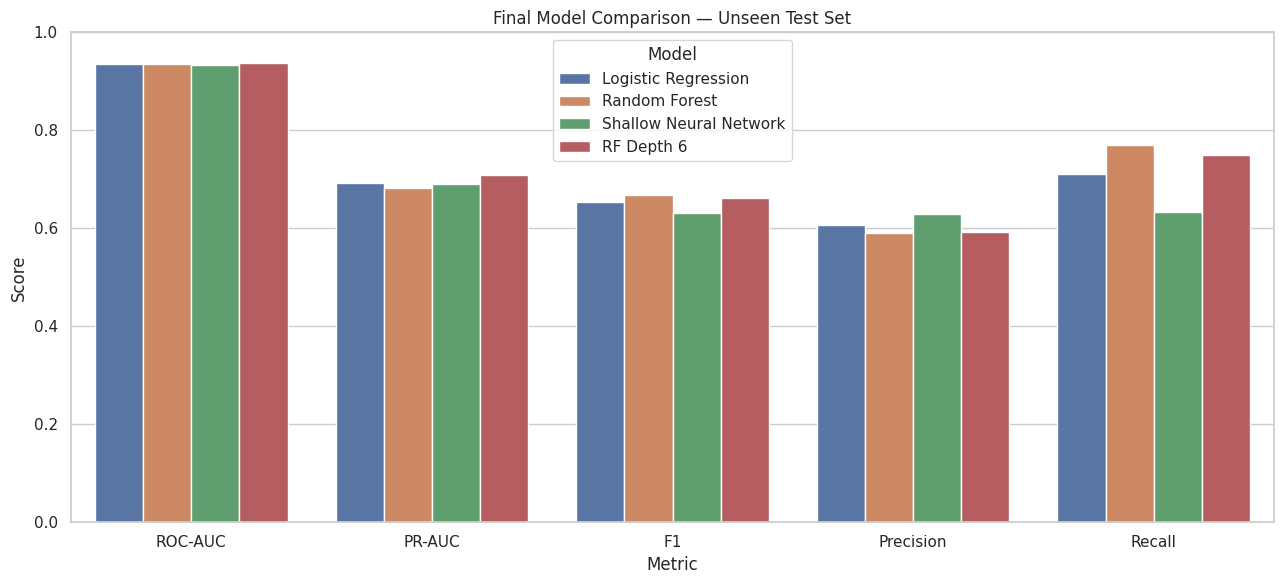

In [74]:

test_results = final_results_df[
    final_results_df["Dataset"] == "Testing"
].copy()

metrics_to_plot = [
    "ROC-AUC",
    "PR-AUC",
    "F1",
    "Precision",
    "Recall"
]

plot_data = test_results.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Final Model Comparison — Unseen Test Set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


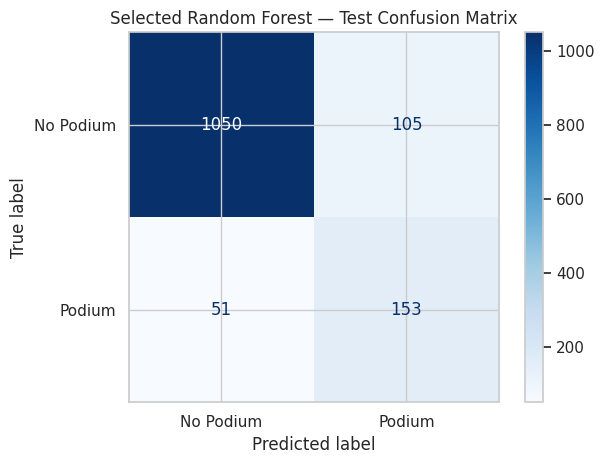

In [75]:

from sklearn.metrics import ConfusionMatrixDisplay

test_predictions = (
    selected_model.predict_proba(X_test)[:, 1]
    >= selected_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No Podium", "Podium"],
    cmap="Blues"
)

plt.title(
    "Selected Random Forest — Test Confusion Matrix"
)
plt.tight_layout()
plt.show()


# 12. Explainable AI (XAI)

We explain the selected Random Forest model using
permutation importance, SHAP, and LIME.

Global explanations show which features influence
model predictions overall.

Local explanations show which features contribute
to a specific driver's predicted podium probability.

These explanations describe model behavior,
not causal relationships.

In [76]:

%pip -q install shap lime

import shap
import lime
import lime.lime_tabular

from sklearn.inspection import permutation_importance

print("XAI libraries imported successfully!")


Note: you may need to restart the kernel to use updated packages.
XAI libraries imported successfully!


,Feature,Importance,Std
2,grid_position,0.103265,0.041231
4,qualifying_position,0.075105,0.036790
6,constructor_form5,0.042759,0.018947
5,driver_form5,0.032670,0.015574
8,driver_rank_pre,0.030165,0.025101
11,constructorId,0.021194,0.025796
9,constructor_points_pre,0.018597,0.008391
10,constructor_rank_pre,0.017534,0.019321
7,driver_points_pre,0.017265,0.007651
1,round,0.005641,0.004065


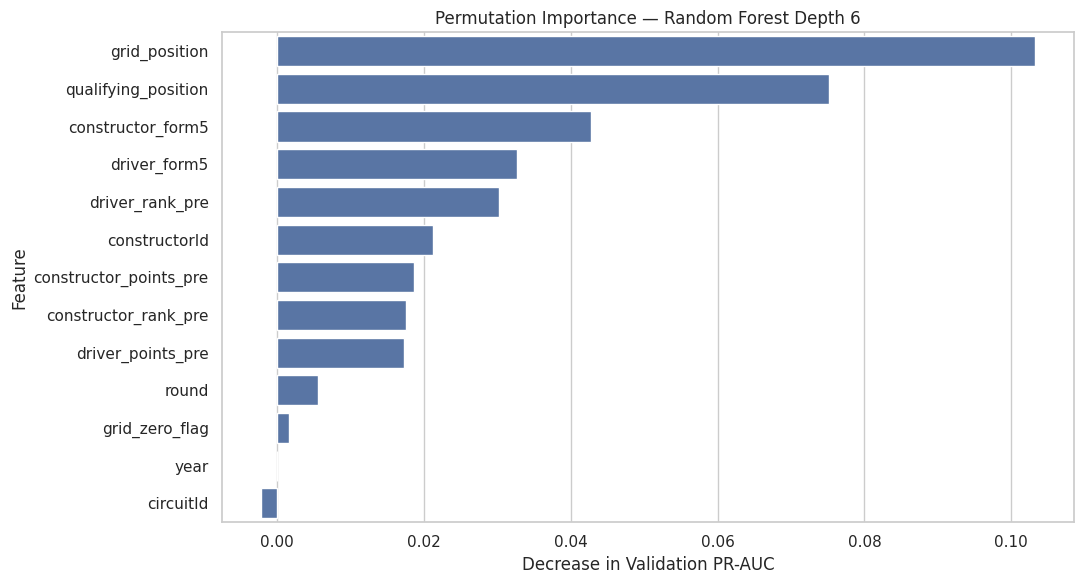

In [77]:

# Use the already selected final model

def pr_auc_scoring(estimator, X, y):
    probabilities = estimator.predict_proba(X)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y, probabilities
    )

    return auc(recall, precision)


perm_result = permutation_importance(
    selected_model,
    X_val,
    y_val,
    scoring=pr_auc_scoring,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Importance — Random Forest Depth 6")
plt.xlabel("Decrease in Validation PR-AUC")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


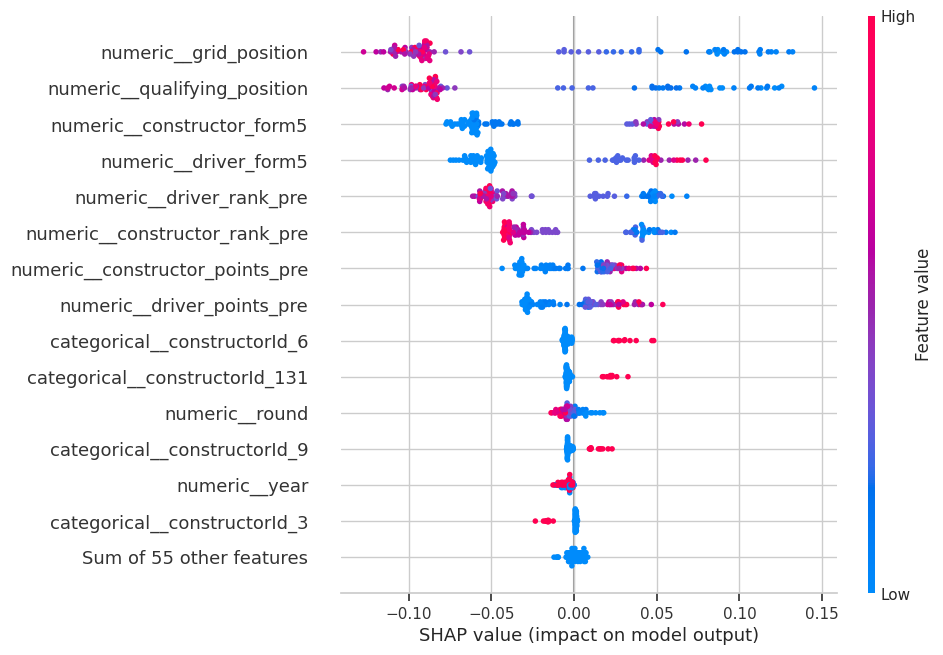

SHAP feature names corrected!


In [78]:

# Sample validation records for efficient explanations
X_shap = X_val.sample(
    n=min(100, len(X_val)),
    random_state=42
)

# Access fitted preprocessing and model
fitted_prep = selected_model.named_steps[
    "preprocessor"
]

rf_classifier = selected_model.named_steps[
    "classifier"
]

# Apply the fitted transformations
X_shap_processed = fitted_prep.transform(
    X_shap
)

# Convert to a dense array if necessary
if hasattr(X_shap_processed, "toarray"):
    X_shap_processed = X_shap_processed.toarray()

feature_names = fitted_prep.get_feature_names_out()

# Create SHAP explanations

# Preserve transformed feature names
X_shap_named = pd.DataFrame(
    X_shap_processed,
    columns=feature_names,
    index=X_shap.index
)

explainer = shap.TreeExplainer(
    rf_classifier
)

shap_values = explainer(
    X_shap_named
)

# Extract podium-class SHAP values
if shap_values.values.ndim == 3:
    class_shap = shap_values[:, :, 1]
else:
    class_shap = shap_values

# Create explanation with explicit feature names
podium_shap = shap.Explanation(
    values=class_shap.values,
    base_values=class_shap.base_values,
    data=X_shap_named.to_numpy(),
    feature_names=list(feature_names)
)

# Global explanation
shap.plots.beeswarm(
    podium_shap,
    max_display=15
)

print("SHAP feature names corrected!")


Predicted podium probability: 0.931

Original input features:


,year,round,grid_position,grid_zero_flag,qualifying_position,driver_form5,constructor_form5,driver_points_pre,driver_rank_pre,constructor_points_pre,constructor_rank_pre,constructorId,circuitId
24649,2020,7,1.0,0,1.0,1.0,0.9,132.0,1.0,221.0,1.0,131,13


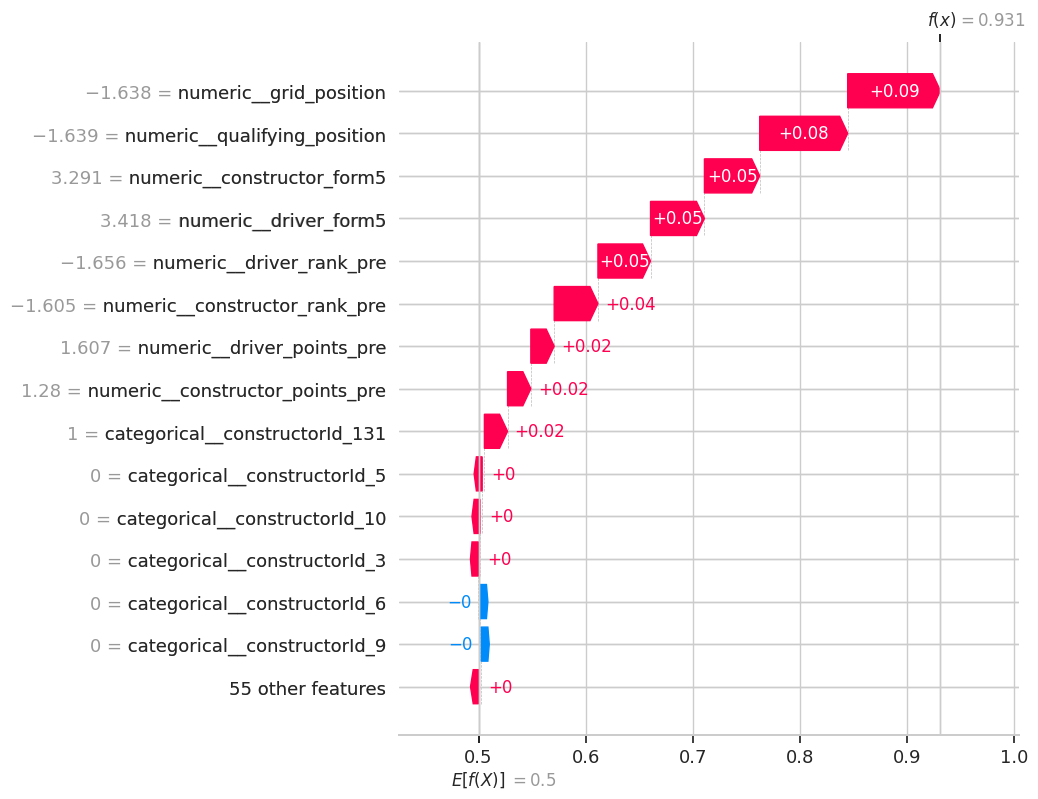

In [79]:

# Select a prediction from the SHAP sample
sample_probabilities = selected_model.predict_proba(
    X_shap
)[:, 1]

# Choose the record with the highest podium probability
local_index = int(np.argmax(sample_probabilities))

print(
    "Predicted podium probability:",
    round(sample_probabilities[local_index], 4)
)

print("\nOriginal input features:")
display(X_shap.iloc[[local_index]])

# Explain that prediction
shap.plots.waterfall(
    podium_shap[local_index],
    max_display=15
)


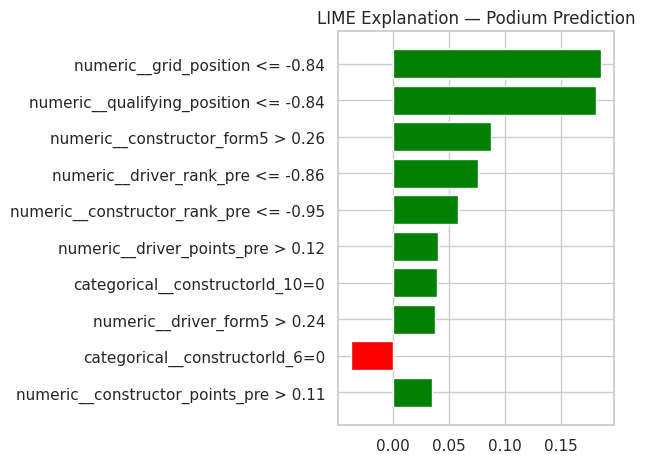

In [80]:

# Transform training data
X_train_processed = fitted_prep.transform(X_train)

if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

# Mark one-hot encoded columns as categorical
categorical_indices = [
    i for i, name in enumerate(feature_names)
    if name.startswith("categorical__")
]

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=list(feature_names),
    class_names=["No Podium", "Podium"],
    categorical_features=categorical_indices,
    mode="classification",
    random_state=42
)

# Explain the same selected validation record
lime_explanation = lime_explainer.explain_instance(
    data_row=np.asarray(
        X_shap_processed[local_index]
    ),
    predict_fn=rf_classifier.predict_proba,
    num_features=10,
    labels=(1,)
)

fig = lime_explanation.as_pyplot_figure(label=1)
plt.title("LIME Explanation — Podium Prediction")
plt.tight_layout()
plt.show()



### XAI Findings and Interpretation

Permutation importance identified starting grid position
and qualifying position as the most influential original
features in the selected Random Forest model.

Global SHAP analysis supported this finding, showing
that favorable grid positions, qualifying performance,
recent driver form, and constructor form contribute
positively to predicted podium probability.

For the selected local prediction, the model estimated
a podium probability of 93.1%. The SHAP waterfall plot
showed positive contributions from grid position,
qualifying position, constructor form, and driver form.

LIME also identified grid position and qualifying
performance among the strongest local contributors.

These explanations describe associations learned by
the model. They do not establish that individual
features causally determine podium finishes.


# 13. Inference Function

This section demonstrates podium prediction using
the selected Random Forest Depth 6 model.

The function supports complete and partially missing
pre-race feature records, applying the same
preprocessing used during training.

In [81]:

def predict_podium(driver_data):

    # Convert input dictionary to a DataFrame
    record = pd.DataFrame(
        [driver_data]
    ).reindex(columns=features)

    # Identify missing input features
    missing_features = (
        record.columns[
            record.isna().iloc[0]
        ].tolist()
    )

    # Use final model and fitted preprocessing
    probability = selected_model.predict_proba(
        record
    )[0, 1]

    prediction = int(
        probability >= selected_threshold
    )

    return {
        "podium_probability": round(
            float(probability), 4
        ),
        "predicted_class": prediction,
        "prediction": (
            "Podium" if prediction == 1
            else "No Podium"
        ),
        "missing_features": missing_features
    }

print("Inference function created successfully!")


Inference function created successfully!


In [82]:

# Find validation records with no missing features
complete_candidates = X_val.dropna(
    subset=features
)

print(
    "Fully complete validation records:",
    len(complete_candidates)
)

assert len(complete_candidates) > 0, (
    "No complete records available."
)

# Select a genuinely complete record
complete_record = complete_candidates.iloc[0].to_dict()

complete_prediction = predict_podium(
    complete_record
)

print("Complete Record Prediction:")
print(complete_prediction)

# Verify that nothing is missing
assert complete_prediction["missing_features"] == []

# Compare with direct model prediction
direct_probability = selected_model.predict_proba(
    complete_candidates.iloc[[0]]
)[0, 1]

assert np.isclose(
    complete_prediction["podium_probability"],
    direct_probability,
    atol=0.0001
)

print("Complete-record validation passed!")


Fully complete validation records: 719
Complete Record Prediction:
{'podium_probability': 0.8847, 'predicted_class': 1, 'prediction': 'Podium', 'missing_features': []}
Complete-record validation passed!


In [83]:

# Copy the genuinely complete record
partial_record = complete_record.copy()

removed_features = [
    "qualifying_position",
    "driver_form5",
    "constructor_rank_pre"
]

# Deliberately remove three inputs
for feature in removed_features:
    partial_record.pop(feature)

partial_prediction = predict_podium(
    partial_record
)

print("Partially Missing Record Prediction:")
print(partial_prediction)

assert set(
    partial_prediction["missing_features"]
) == set(removed_features)

assert 0 <= partial_prediction[
    "podium_probability"
] <= 1

print("Partial-record validation passed!")


Partially Missing Record Prediction:
{'podium_probability': 0.5287, 'predicted_class': 0, 'prediction': 'No Podium', 'missing_features': ['qualifying_position', 'driver_form5', 'constructor_rank_pre']}
Partial-record validation passed!
